# Single-nucleus RNA-seq: cell identities and liver zonation in mouse liver

## Overview of the analysis workflow

In this tutorial, we will analyze a published mouse liver transcriptomics dataset using Scanpy, a Python toolkit for single-cell analysis. Starting from an already generated gene-expression count matrix, we will work through the main stages of a standard analysis:
1. **Load and explore the data.** Understand how gene-expression counts and information about individual cells are represented in an AnnData object.
2. **Quality control.** Examine the number of detected genes, total transcript counts and mitochondrial RNA fraction, then filter low-quality observations.
3. **Preprocess the expression matrix.** Normalize for differences in sequencing depth, log-transform the counts and identify highly variable genes.
4. **Explore cellular heterogeneity.** Use principal component analysis (PCA), construct a nearest-neighbor graph, visualize cells using UMAP and identify clusters using Leiden clustering.
5. **Identify cell populations.** Find marker genes associated with each cluster and use known liver markers to annotate cell types.
6. **Investigate hepatocyte zonation.** Examine how the expression of selected genes varies across hepatocyte states and relate these patterns to liver organization.

The tutorial is based on the scanpy documentation: [Scanpy](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html)

### Finding a new scRNA-seq / snRNA-seq dataset

For a project using scRNA-seq or snRNA-seq, a good starting point is a publication that analyzes these data. The paper's Data availability section generally specifies where the authors deposited their data, for example in the Gene Expression Omnibus (GEO) or another public repository. Published datasets often include processed expression matrices, coordinates and imaging data, although the exact files depend on the technology.

Additional resources for discovering scRNA-seq and snRNA-seq datasets and related publications include:
- [cell x gene](https://cellxgene.cziscience.com)
- [BROAD single-cell portal](https://singlecell.broadinstitute.org/single_cell)
- [Human cell atlas](https://data.humancellatlas.org)
- [Tabula Sapiens portal](https://tabula-sapiens.sf.czbiohub.org)
- [Allen brain science](https://brain-map.org)
Before downloading, check the organism, tissue, technology, sample type and available processed files. These details determine which analyses are possible.

## Single-nucleus versus single-cell RNA sequencing

The dataset used here was generated by single-nucleus RNA sequencing (snRNA-seq), which profiles RNA isolated from nuclei rather than whole cells. In contrast, single-cell RNA sequencing (scRNA-seq) captures RNA from intact cells, including cytoplasmic transcripts. snRNA-seq can be particularly useful for tissues that are difficult to dissociate into intact viable cells, such as the liver, and may reduce some dissociation-related effects. However, nuclear RNA contains a different mixture of transcripts, often including more unspliced RNA, and may show different gene-detection and mitochondrial-read characteristics. These differences matter when interpreting quality-control metrics and expression patterns.

The workflow taught here is applicable to both snRNA-seq and scRNA-seq. Most downstream analysis steps are shared, although preprocessing decisions and quality-control thresholds need to be adapted to the assay and dataset.

We will not align FASTQ files or infer gene-regulatory networks. This is an RNA-analysis practical; the course's separate ATAC and enhancer sessions address regulatory DNA.

## Biological question

Mouse liver lobules are organized around portal tracts and central veins. Along this axis, hepatocytes adopt different metabolic transcriptional programs, known as zonation. Can we recover both cell identities and this continuous transcriptional gradient from single-nucleus RNA-seq alone?

**Research questions**

1. What do we learn from gene counts and nucleus-level quality-control measurements?
2. How do normalization, dimensionality reduction and clustering reveal the cell populations in a liver sample?
3. How can marker genes distinguish broad cell identities from transcriptional states within hepatocytes?
4. Can zonation-associated expression patterns be recognized from snRNA-seq even though tissue positions have been lost?

**How to use this notebook.** Follow Parts 1–3 in order. Each part has numbered steps, explanations, short questions and exercises. The data download is cached after the first run. The full table is larger when uncompressed, so loading it may take several minutes.

**Reproducibility:** after changing preprocessing parameters, restart the kernel and run the notebook from the top. Figures and numbers already saved in this teaching copy illustrate a completed example; interpret the values from your own run.

## Main paper

Bravo González-Blas et al. (2024), Nature Cell Biology, doi:10.1038/s41556-023-01316-4. The study combined snRNA-seq, ATAC, multiome and spatial smFISH. We use its snRNA-seq count matrix, GEO GSE218465, not the multiome matrix. The source series contains four 10x snRNA-seq libraries from mouse liver, each with its own GEO sample record: GSM6745644 (7b2a3b), GSM6745645 (7703fe), GSM6745646 (02ff09) and GSM6745647 (922e80). GEO provides one processed, combined gene-by-nucleus count table, GSE218465_scrna_counts.tsv.gz, rather than a separate table for each library. Our tutorial loads the entire combined table (16,900 nuclei); we do not merge four datasets ourselves. Crucially, the nucleus identifiers preserve the library code, so we can recover which library each nucleus came from and check whether differences between libraries contribute to the observed clustering.

## Part 1: Obtain the data, explore the matrix and perform quality control

### Selecting the kernel and installing the Python environment

As in the other course practicals, we use a dedicated **Conda/Mamba environment** named `regulatory_genomics`. Using a consistent environment helps ensure that each notebook runs with the necessary scientific Python packages. You only need to create it **once**.

If you **already created `regulatory_genomics` for the spatial-transcriptomics practical**, keep it. In a terminal, activate it and add `seaborn` if needed:

```bash
conda activate regulatory_genomics
mamba install -n regulatory_genomics -c conda-forge seaborn
```

If you **have not yet created this environment**, run the following in a **terminal on the computer/VSC cluster where you use Jupyter**, not in a notebook code cell:

```bash
mamba create -n regulatory_genomics -c conda-forge python=3.11 scanpy "squidpy>=1.8,<1.9" anndata numpy scipy "pandas>=2.2,<3" matplotlib seaborn "scikit-image>=0.26,<0.27" h5py python-igraph leidenalg ipykernel ipywidgets
```

`squidpy` and the image-analysis packages are included so that this environment can also be used for the companion spatial notebook. If `mamba` is not available, use `conda create` (or `conda install`) instead. The installation may take several minutes.

Activate the environment and **register a Jupyter kernel**:

```bash
conda activate regulatory_genomics
python -m ipykernel install --user --name regulatory_genomics --display-name "Python (regulatory_genomics)"
jupyter kernelspec list
```

Then open the notebook in VS Code or Jupyter and choose **Python (regulatory_genomics)** via **Select Kernel** (VS Code) or **Kernel → Change Kernel** (Jupyter). If that kernel was already registered, simply select it; you do not need to install it again.

We will verify the Python and Scanpy versions in the first code cell. If an import fails, ensure that Jupyter is using the environment in which you installed the packages.

### Step 0: Set up the working directory

We will store downloaded counts in `data/` and analyzed results in `results/scrna_liver/` within your course folder. The input table is downloaded only once. Its 43.1 MB compressed TSV expands substantially, so allow disk space and a few minutes for loading.

The next cell uses the **current working directory** so it works for different students and VSC usernames. Look at the printed path. If Jupyter starts in a different folder, change only the `PROJECT` line to point to your own writable course directory.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad

# By default, use the folder from which the notebook kernel was started.
# If necessary, replace this with your own writable course folder.
PROJECT = Path.cwd().resolve()
DATA = PROJECT / "data"
RESULTS = PROJECT / "results" / "scrna_liver"
DATA.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=90, facecolor="white")
print("Python:", sys.version.split()[0])
print("Scanpy:", sc.__version__)
print("Working directory:", Path.cwd())
print("Project:", PROJECT)
print("If this is not your course folder, edit PROJECT above before downloading data.")

Python: 3.11.18
Scanpy: 1.11.5
Working directory: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course
Project: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course
If this is not your course folder, edit PROJECT above before downloading data.


/tmp/ipykernel_1667169/1208554007.py:22: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


### Step 1: Download and inspect the published count matrix

In the original experiment, RNA was isolated from individual nuclei, converted to sequencing libraries, and processed to assign sequencing reads to genes and nuclei. Our input is already a UMI count matrix: rows represent genes and columns represent nuclei. Thus, read alignment and UMI deduplication have already taken place.

The published file is GSE218465_scrna_counts.tsv.gz. Its GEO record provides the exact source and data provenance. We convert it to Scanpy's AnnData, which expects cells × genes, and store it as sparse data.

The following code loads the published count matrix and converts it into a format suitable for Scanpy. You do not need to understand every line of the import procedure. We will focus on exploring and analyzing the resulting AnnData object.

In [2]:
from urllib.request import urlretrieve

url = ("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218465/"
       "suppl/GSE218465_scrna_counts.tsv.gz")
counts_file = DATA / "GSE218465_scrna_counts.tsv.gz"
if not counts_file.exists():
    print("Downloading processed GEO counts…")
    urlretrieve(url, counts_file)
print(f"Count matrix file: {counts_file} ({counts_file.stat().st_size / 1e6:.1f} MB)")
pd.read_csv(counts_file, sep="\t", compression="gzip", nrows=3).iloc[:, :7]

Count matrix file: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/data/GSE218465_scrna_counts.tsv.gz (45.2 MB)


,AAACCCACACCCTAAA-TEW__02ff09__scNuc_Liver_Habib_Control,AAACCCACAGACACCC-TEW__02ff09__scNuc_Liver_Habib_Control,AAACCCAGTTACCGTA-TEW__02ff09__scNuc_Liver_Habib_Control,AAACCCAGTTGTTGAC-TEW__02ff09__scNuc_Liver_Habib_Control,AAACCCATCGCATTAG-TEW__02ff09__scNuc_Liver_Habib_Control,AAACGAAAGCCGTCGT-TEW__02ff09__scNuc_Liver_Habib_Control,AAACGAAAGGGAGATA-TEW__02ff09__scNuc_Liver_Habib_Control
0610005C13Rik,3,4,0,0,8,1,2
0610006L08Rik,0,0,0,0,0,0,0
0610009B22Rik,0,1,1,0,0,0,0


### Step 2: Read the count matrix into AnnData

The downloaded matrix has genes in rows and nuclei in columns. Scanpy expects observations × variables, so we transpose it. To avoid converting the entire dataset to a large dense matrix, we import in small chunks and store the nonzero counts in a sparse matrix.

### Efficient import into AnnData

The GEO TSV is genes × nuclei. Loading it directly as one large pandas DataFrame may use considerable RAM. We read small blocks of genes and convert each block into a sparse matrix before transposing. The first column is expected to contain gene names; the remaining columns contain counts. If GEO changes its table schema, inspect the preview above before continuing.

In [3]:
cache = DATA / "GSE218465_scrna_raw.h5ad"
if cache.exists():
    adata = sc.read_h5ad(cache)
else:
    blocks, gene_names, cell_names = [], [], None
    for block in pd.read_csv(counts_file, sep="\t", compression="gzip",
                             index_col=0, chunksize=128):
        if cell_names is None:
            cell_names = block.columns.astype(str).to_list()
        gene_names.extend(block.index.astype(str).to_list())
        numeric = block.to_numpy(dtype=np.float32)
        blocks.append(sp.csr_matrix(numeric))
    # Sparse input remains sparse: no whole-matrix .todense() conversion.
    gene_by_cell = sp.vstack(blocks, format="csr")
    adata = ad.AnnData(X=gene_by_cell.T.tocsr(),
                      obs=pd.DataFrame(index=cell_names),
                      var=pd.DataFrame(index=gene_names))
    adata.var_names_make_unique()
    adata.obs_names_make_unique()
    adata.write_h5ad(cache, compression="gzip")
    del blocks, gene_by_cell

print(adata)
print("Nuclei:", adata.n_obs, "Genes:", adata.n_vars)
print("Sparse storage:", sp.issparse(adata.X))
print("First genes:", adata.var_names[:8].tolist())

AnnData object with n_obs × n_vars = 16900 × 22475
Nuclei: 16900 Genes: 22475
Sparse storage: True
First genes: ['0610005C13Rik', '0610006L08Rik', '0610009B22Rik', '0610009E02Rik', '0610009L18Rik', '0610010F05Rik', '0610010K14Rik', '0610012D04Rik']


### Step 3: Explore nucleus and gene metadata

adata.X contains expression counts; adata.obs describes nuclei; adata.var describes genes; adata.obsm stores PCA and UMAP coordinates. First inspect the data structure. A zero count means a transcript was not detected.

Inspect the observed metadata. Every row corresponds to a nucleus

In [4]:
adata.obs.head()

""
AAACCCACACCCTAAA-TEW__02ff09__scNuc_Liver_Habib_Control
AAACCCACAGACACCC-TEW__02ff09__scNuc_Liver_Habib_Control
AAACCCAGTTACCGTA-TEW__02ff09__scNuc_Liver_Habib_Control
AAACCCAGTTGTTGAC-TEW__02ff09__scNuc_Liver_Habib_Control
AAACCCATCGCATTAG-TEW__02ff09__scNuc_Liver_Habib_Control


#### Identifying the four sequencing libraries
The GEO count matrix already contains nuclei from the four snRNA-seq libraries. However, because its metadata table does not contain a separate library column, we need to recover that information from the nucleus identifiers (the row names in adata.obs).

For example, the identifier AAACCCACACCCTAAA-TEW__02ff09__scNuc_Liver_Habib_Control contains the library code 02ff09. We extract the six-character code between the double underscores, match it to the corresponding GEO sample and count how many nuclei originate from each library.

Why does this matter? Library-to-library differences in capture, sequencing depth or nuclei quality can influence dimensionality reduction and clustering. Recording sample origin lets us look for these effects, even though this introductory tutorial does not perform batch correction.

In [5]:
# Map the identifiers embedded in nucleus names to the GEO sample records.
library_to_GSM = {
    "7b2a3b": "GSM6745644",
    "7703fe": "GSM6745645",
    "02ff09": "GSM6745646",
    "922e80": "GSM6745647",
}

# Example nucleus ID: AAACCCACACCCTAAA-TEW__02ff09__scNuc_Liver_Habib_Control
adata.obs["library"] = adata.obs_names.str.extract(
    r"__(7b2a3b|7703fe|02ff09|922e80)__", expand=False
)
adata.obs["GEO_sample"] = adata.obs["library"].map(library_to_GSM)

library_counts = (
    adata.obs.groupby(["library", "GEO_sample"], dropna=False, observed=True)
    .size()
    .rename("n_nuclei")
    .reset_index()
    .sort_values("GEO_sample")
)
display(library_counts)
print("Unrecognized library codes:", adata.obs["library"].isna().sum())

,library,GEO_sample,n_nuclei
2,7b2a3b,GSM6745644,3893
1,7703fe,GSM6745645,4250
0,02ff09,GSM6745646,4971
3,922e80,GSM6745647,3786


Unrecognized library codes: 0


The table shows how many nuclei from each original 10x library are represented in the combined, published count matrix. The sample identifiers should match the four GEO records listed above. Differences in the number of retained nuclei can arise from library preparation, capture efficiency or upstream filtering; they should not be interpreted directly as differences in cell-type abundance in the tissue.

At this stage we have identified the libraries, but we have not evaluated or corrected possible batch effects. Later, we will compare their distributions on the UMAP.

**Question:** Why is it useful to recover the four original sequencing libraries from nucleus identifiers even when GEO provides one combined count matrix?

The variable table contains **gene-level metadata**, one row per gene.

In [6]:
adata.var.head()

""
0610005C13Rik
0610006L08Rik
0610009B22Rik
0610009E02Rik
0610009L18Rik


Access expression values from adata.X. Convert only a tiny slice to a dense table.

In [7]:
pd.DataFrame(adata[:5, :5].X.toarray(), index=adata.obs_names[:5], columns=adata.var_names[:5])

,0610005C13Rik,0610006L08Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik
AAACCCACACCCTAAA-TEW__02ff09__scNuc_Liver_Habib_Control,3.0,0.0,0.0,0.0,0.0
AAACCCACAGACACCC-TEW__02ff09__scNuc_Liver_Habib_Control,4.0,0.0,1.0,0.0,0.0
AAACCCAGTTACCGTA-TEW__02ff09__scNuc_Liver_Habib_Control,0.0,0.0,1.0,0.0,0.0
AAACCCAGTTGTTGAC-TEW__02ff09__scNuc_Liver_Habib_Control,0.0,0.0,0.0,0.0,0.0
AAACCCATCGCATTAG-TEW__02ff09__scNuc_Liver_Habib_Control,8.0,0.0,0.0,0.0,0.0


### Step 4: Calculate quality-control metrics

Each nucleus is represented by a gene-expression profile containing the number of RNA molecules detected for each gene. Unique molecular identifiers (UMIs) are used to estimate the number of original RNA molecules, reducing the effects of PCR amplification.

During quality control, we examine the total number of UMIs, the number of genes detected and the proportion of mitochondrial transcripts. These measurements help identify nuclei with potentially poor-quality expression profiles.

In [8]:
adata.var["mt"] = adata.var_names.str.lower().str.startswith("mt-")
adata.var["ribo"] = adata.var_names.str.match(r"(?i)^rp[sl]")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"],
                           percent_top=None, log1p=True, inplace=True)
display(adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]].describe().round(2))

,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo
count,16900.00,16900.00,16900.00,16900.00
mean,7330.89,2739.13,2.24,0.51
std,6572.30,1472.40,2.21,0.40
min,500.00,383.00,0.00,0.00
25%,2424.00,1490.75,0.58,0.25
50%,4993.00,2525.00,1.44,0.36
75%,10622.00,3878.25,3.36,0.60
max,56693.00,7720.00,10.00,5.54


View the distribution of QC metrics before setting thresholds.

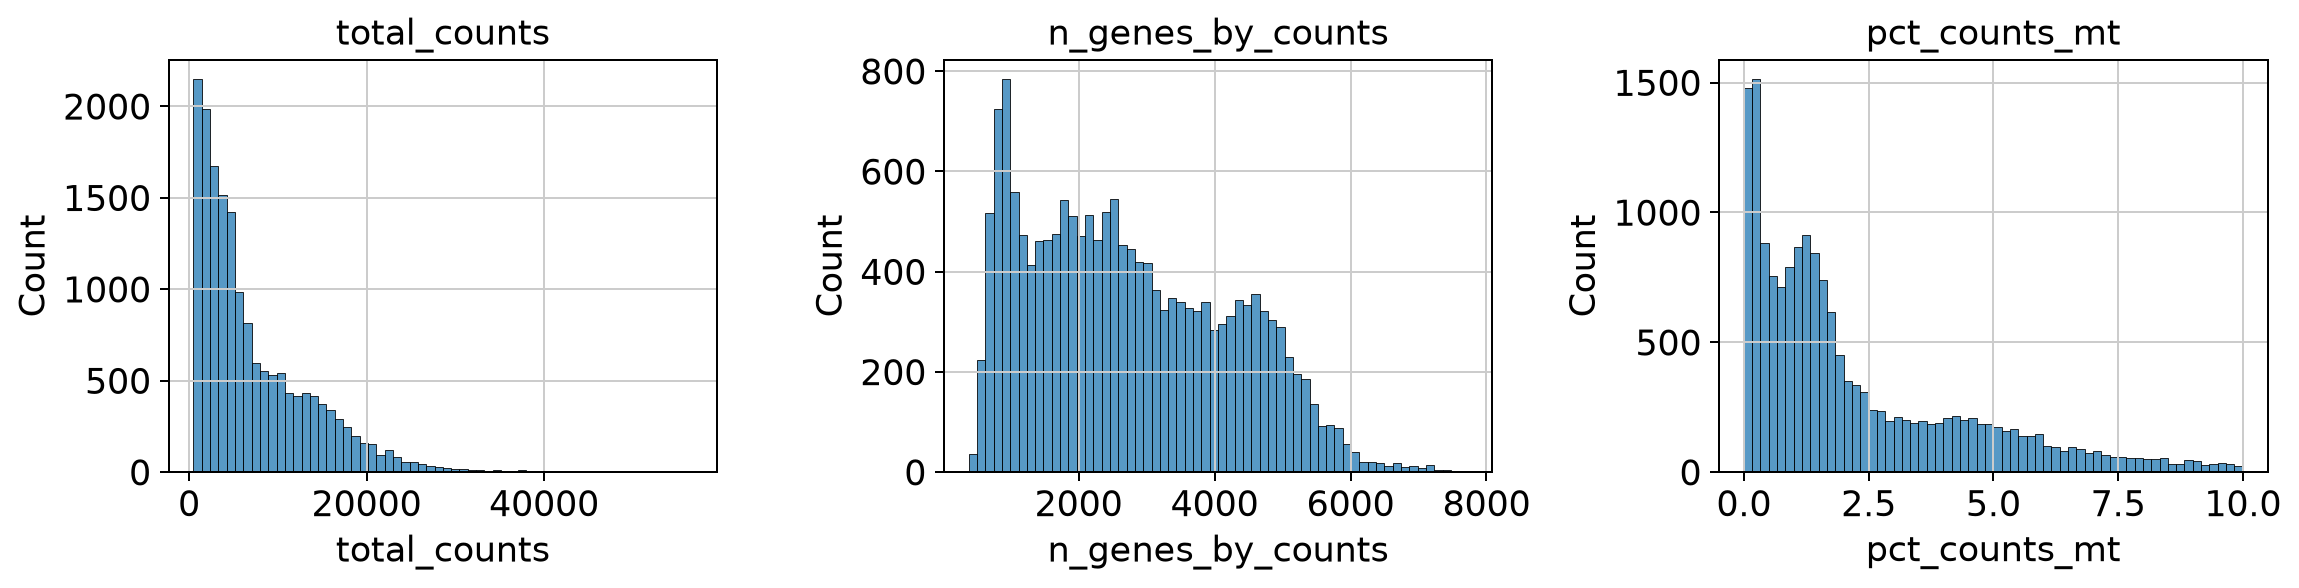

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, col in zip(ax, ["total_counts", "n_genes_by_counts", "pct_counts_mt"]):
    sns.histplot(adata.obs[col], bins=60, ax=a)
    a.set_title(col)
plt.tight_layout()

Total UMI counts are right-skewed, and nuclei vary considerably in the number of genes detected. Most nuclei have low mitochondrial fractions, as expected for a nuclear RNA assay, although a subset approaches 10%. These distributions help motivate QC thresholds, but do not by themselves tell us whether the nuclei represent different cell types or different levels of data quality.

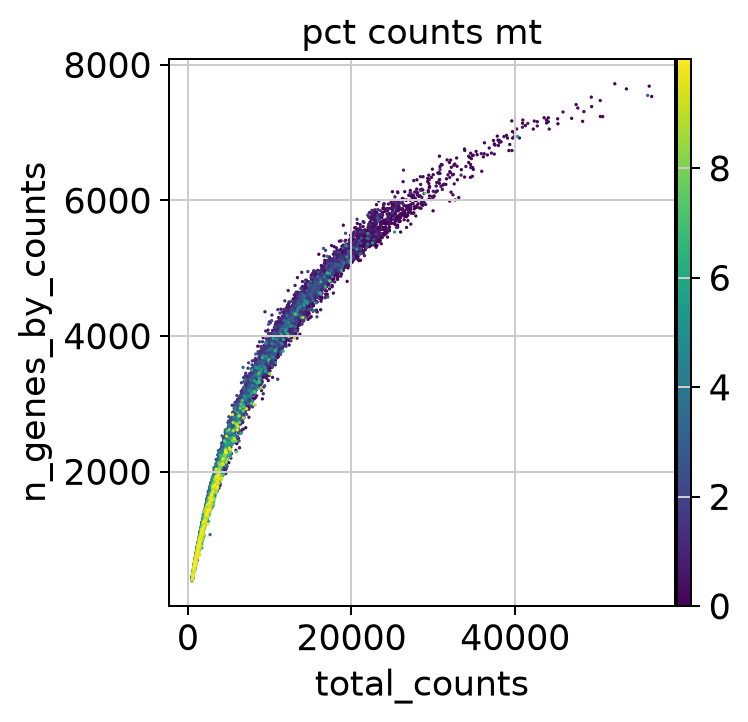

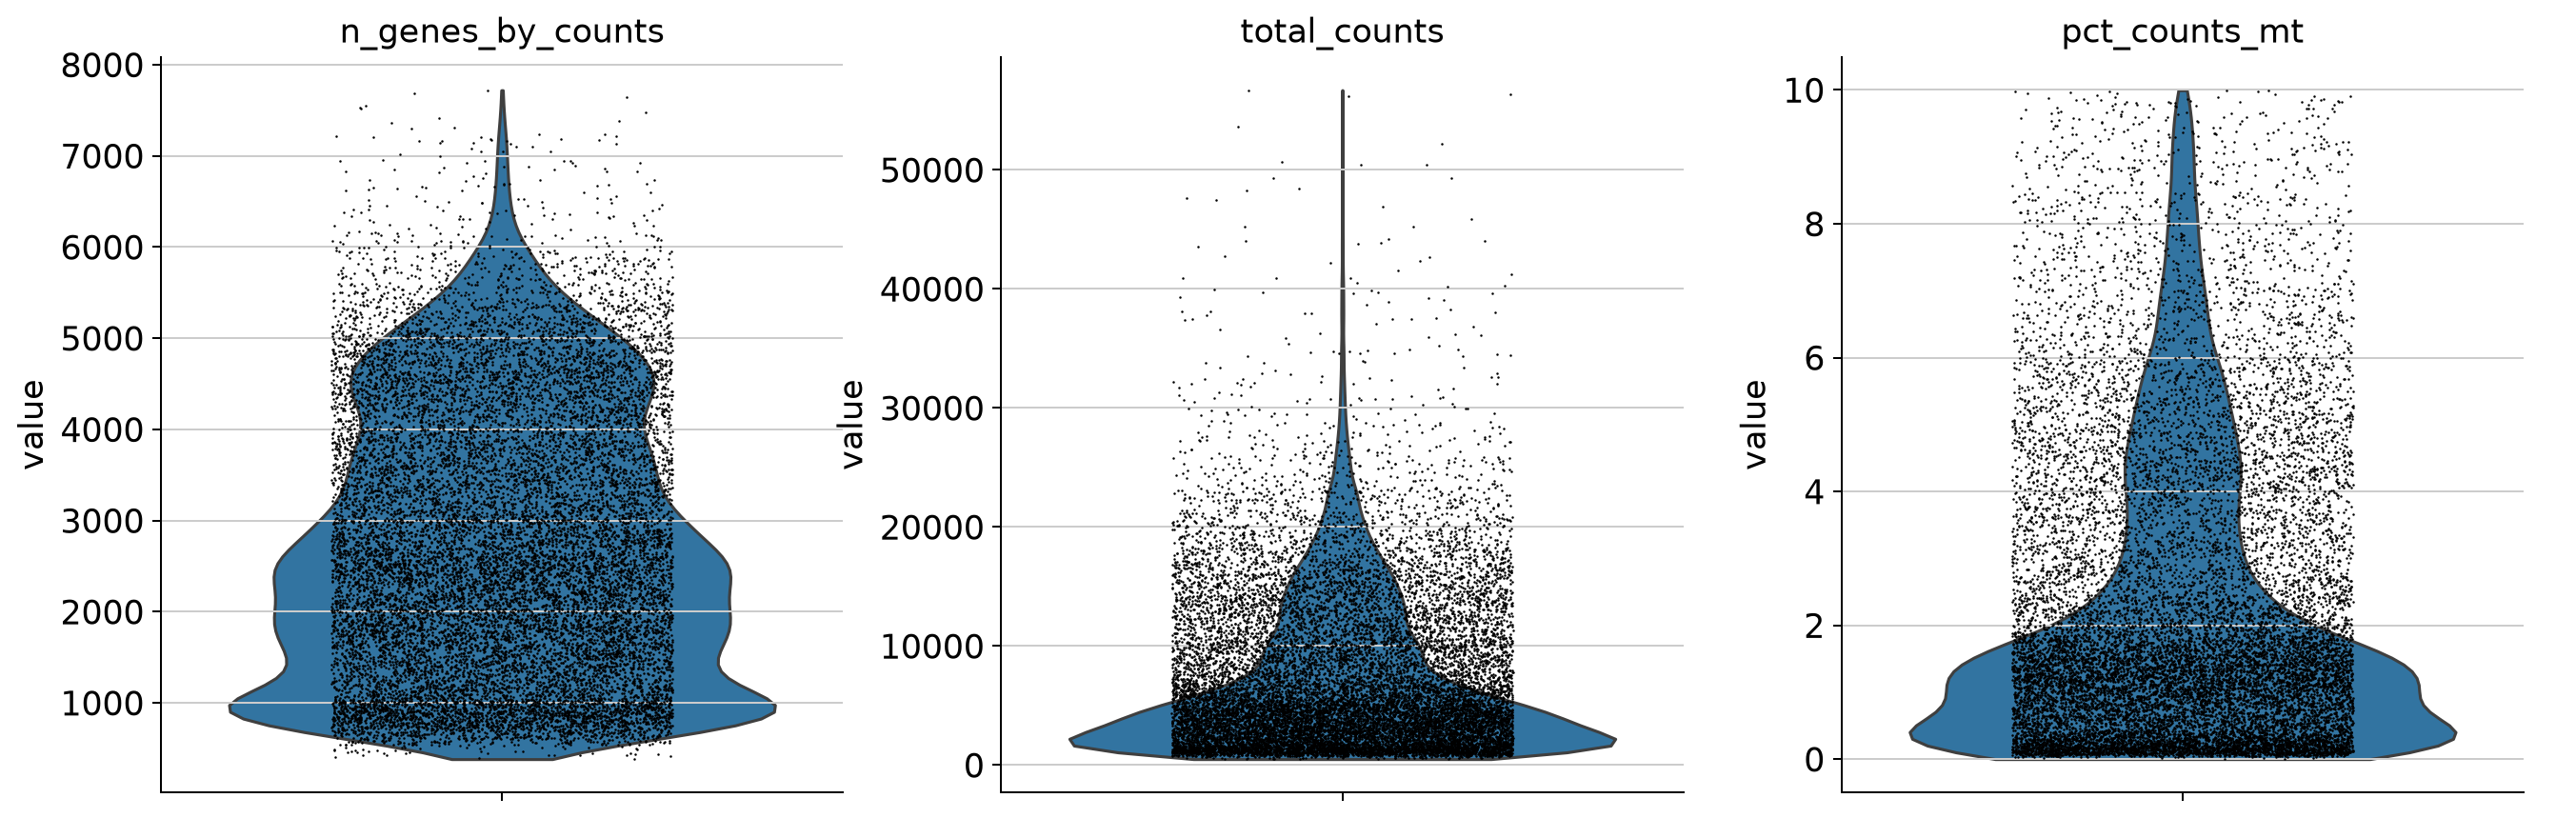

In [10]:
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.25, multi_panel=True)

The number of detected genes rises with UMI depth, although the relationship becomes less steep at high counts. Some low-count nuclei have comparatively high mitochondrial fractions. The violin plots show that there is no sharp boundary separating clearly good and bad nuclei. Thresholds therefore require both biological and technical justification.

**Question:** Why is a high mitochondrial RNA fraction often a warning sign in single-cell RNA-seq, and why can the expected fraction differ in snRNA-seq?

### Step 5: Filter nuclei and genes

The paper initially used at least 350 detected genes and less than 10% mitochondrial counts, followed by further QC and doublet analysis. These are example thresholds, not universal rules. 

In [11]:
MIN_GENES = 350
MAX_MT = 10.0

# If this cell is rerun after normalization, restore original UMI counts first.
if "counts" in adata.layers:
    adata.X = adata.layers["counts"].copy()
    adata.raw = None
    adata.uns.pop("log1p", None)

keep = ((adata.obs["n_genes_by_counts"] >= MIN_GENES) &
        (adata.obs["pct_counts_mt"] < MAX_MT))
print(f"Retaining {keep.sum():,} / {len(keep):,} nuclei ({100 * keep.mean():.1f}%).")
adata = adata[keep].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["counts"] = adata.X.copy()
print(adata)

Retaining 16,900 / 16,900 nuclei (100.0%).
filtered out 1864 genes that are detected in less than 3 cells
AnnData object with n_obs × n_vars = 16900 × 20611
    obs: 'library', 'GEO_sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'


 All 16,900/16,900 nuclei (100%) pass the chosen threshold of at least 350 genes and less than 10% mitochondrial counts. This is consistent with the public gene-count matrix already having undergone upstream cell/nucleus filtering; it is not evidence that every captured nucleus was high quality. We remove 1,864 very rarely detected genes. This tutorial does not reconstruct the original study's complete QC, doublet detection or sample-level filtering.

**Question:** If 100% of published nuclei pass our QC thresholds, does that mean the original experiment contained no low-quality nuclei? Why or why not?

## Part 2: Normalize data, identify cell types and compare libraries

### Step 6: Normalize and log-transform expression

Count depth differs between nuclei. We normalize each nucleus to 10,000 counts and use log1p to reduce the leverage of very abundant genes. Original UMI counts are preserved in `adata.layers["counts"]`; normalized values are no longer integer UMIs.

**Important when rerunning cells:** Scanpy modifies `adata.X` in place. Therefore, we restore the original counts from `layers["counts"]` **before every normalization**. Otherwise, running this cell twice would normalize data that had already been normalized and log-transformed.

In [12]:
# Always start from original UMI counts, even if this cell was run before.
adata.X = adata.layers["counts"].copy()
adata.uns.pop("log1p", None)  # Reset Scanpy's log-transform tracking.

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()  # Full log-normalized gene space for markers later.
print(adata)

normalizing counts per cell


    finished (0:00:00)
AnnData object with n_obs × n_vars = 16900 × 20611
    obs: 'library', 'GEO_sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'log1p'
    layers: 'counts'


Compare the first few transformed entries with the integer count table from the beginning.

In [13]:
pd.DataFrame(adata[:5, :5].X.toarray(), index=adata.obs_names[:5], columns=adata.var_names[:5])

,0610005C13Rik,0610006L08Rik,0610009B22Rik,0610010F05Rik,0610012D04Rik
AAACCCACACCCTAAA-TEW__02ff09__scNuc_Liver_Habib_Control,1.576864,0.0,0.000000,0.000000,0.0
AAACCCACAGACACCC-TEW__02ff09__scNuc_Liver_Habib_Control,1.708430,0.0,0.756155,1.181771,0.0
AAACCCAGTTACCGTA-TEW__02ff09__scNuc_Liver_Habib_Control,0.000000,0.0,1.992949,0.000000,0.0
AAACCCAGTTGTTGAC-TEW__02ff09__scNuc_Liver_Habib_Control,0.000000,0.0,0.000000,0.000000,0.0
AAACCCATCGCATTAG-TEW__02ff09__scNuc_Liver_Habib_Control,2.079103,0.0,0.000000,0.628428,0.0


### Step 7: Identify highly variable genes

Highly variable genes (HVGs) contain stronger-than-expected variation relative to their average expression. We select them to focus PCA and clustering on informative differences. Inspect the mean–variability relationship.

extracting highly variable genes
    finished (0:00:00)


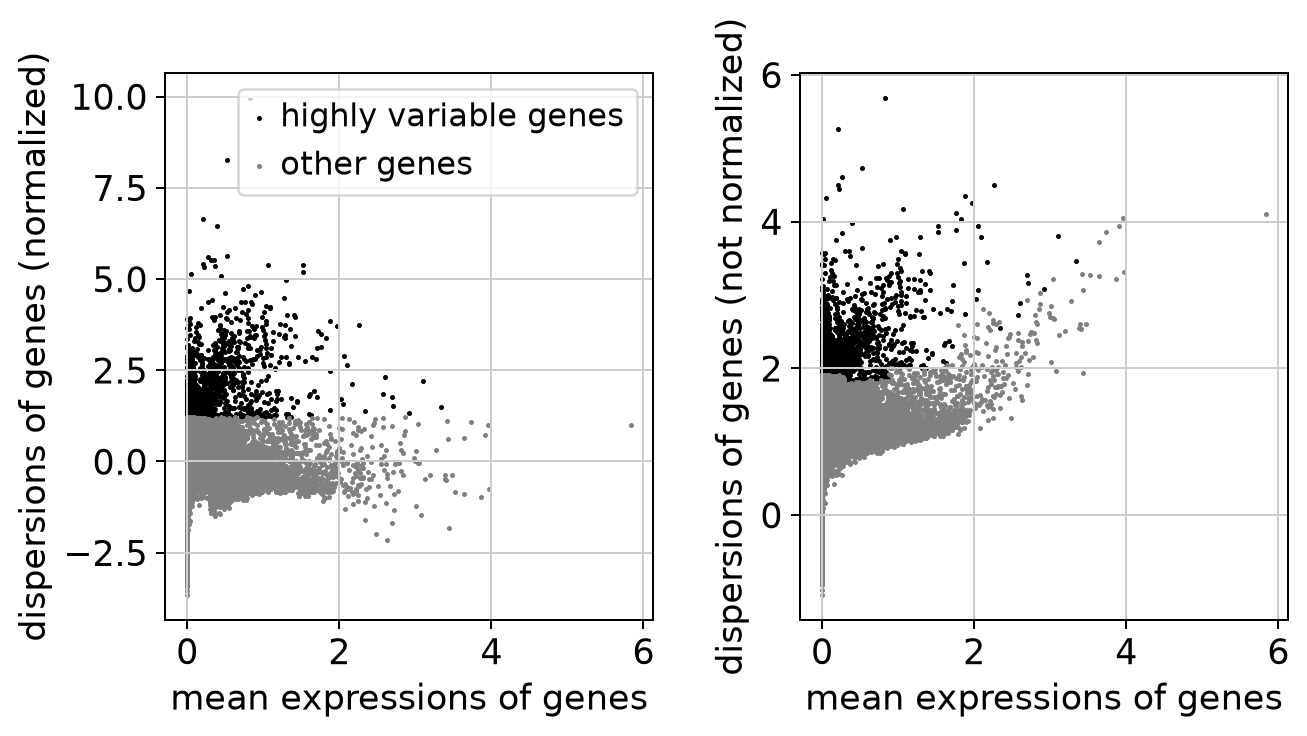

HVGs: 2000


In [14]:
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)
print("HVGs:", adata.var["highly_variable"].sum())
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

The 2,000 selected genes show relatively high dispersion compared with genes of similar mean expression. These genes will be used to construct the low-dimensional representation. This selection does not imply that non-HVGs are biologically unimportant: marker genes outside this set remain available for annotation.

**Question:** Why do we use HVGs for PCA but retain the full gene set when visualizing marker genes?

### Doublet detection (additional QC background)

Doublets occur when two nuclei are captured together, producing a mixed gene-expression profile. Tools such as Scrublet can identify potential doublets by comparing observed transcriptomes with simulated doublets. Unlike low-quality nuclei, doublets may have high UMI counts and many detected genes, making them difficult to identify using standard QC thresholds alone.

In this tutorial, we use a previously processed count matrix and therefore do not repeat the original doublet filtering.

For an example of **doublet detection**, see the Scrublet section of the [Scanpy clustering tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html).

### Step 8: Principal component analysis

We reduce thousands of genes to a smaller set of principal components (PCs) summarizing major variation. PCs can reflect genuine biology or unwanted technical differences. First check the variance explained by each PC.

/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=50
    finished (0:00:02)


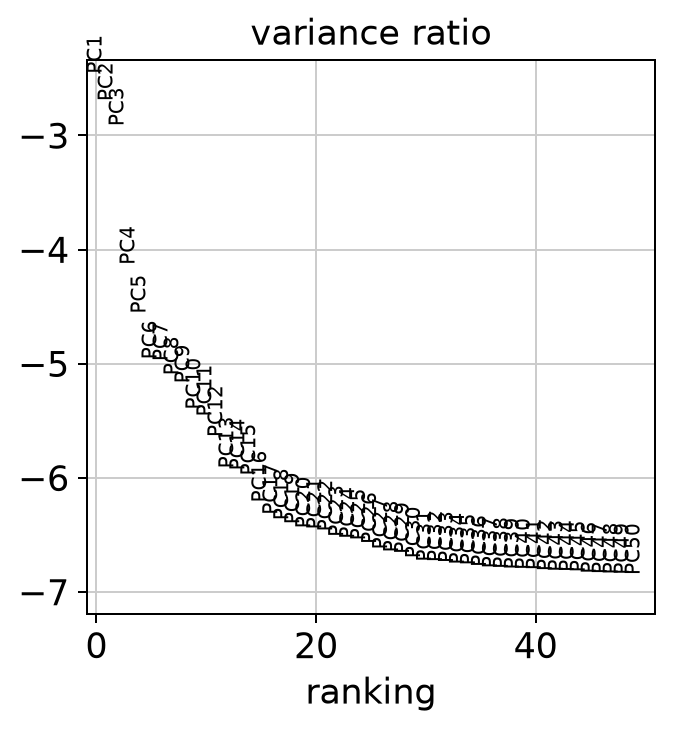

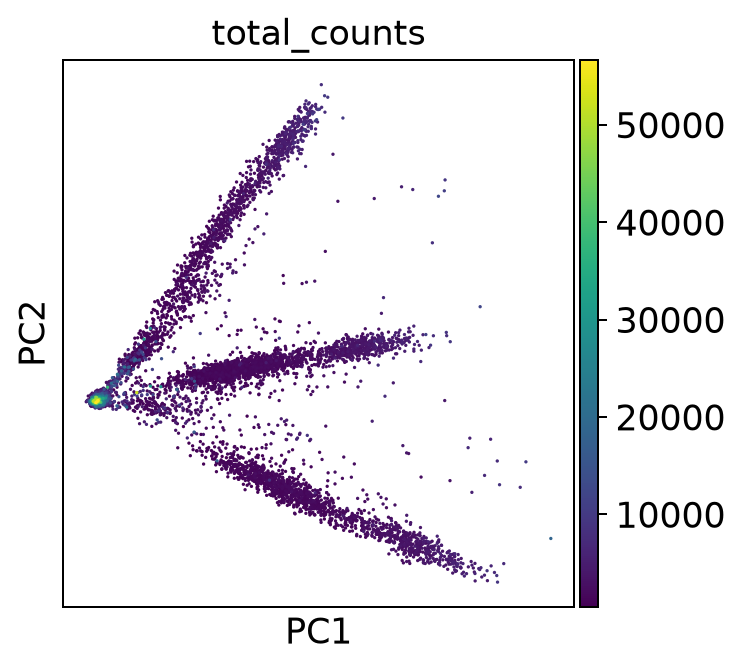

In [15]:
sc.pp.scale(adata_hvg, max_value=10)
sc.pp.pca(adata_hvg, n_comps=50, svd_solver="arpack")
sc.pl.pca_variance_ratio(adata_hvg, log=True, n_pcs=50)
sc.pl.pca(adata_hvg, color="total_counts")

The first few principal components explain substantially more variation than later PCs. The variance declines gradually after the strongest components, without an unambiguous elbow. For the tutorial we retain 30 PCs for the neighbor graph as a practical choice; the result should be checked for robustness. The first two PCs form several branches, and their relationship to UMI depth can be assessed by the color scale, but the axes require gene-loading inspection before biological interpretation.

Inspect PCA loadings to determine whether major PCs are driven by cell-identity markers, sequencing depth or other effects.

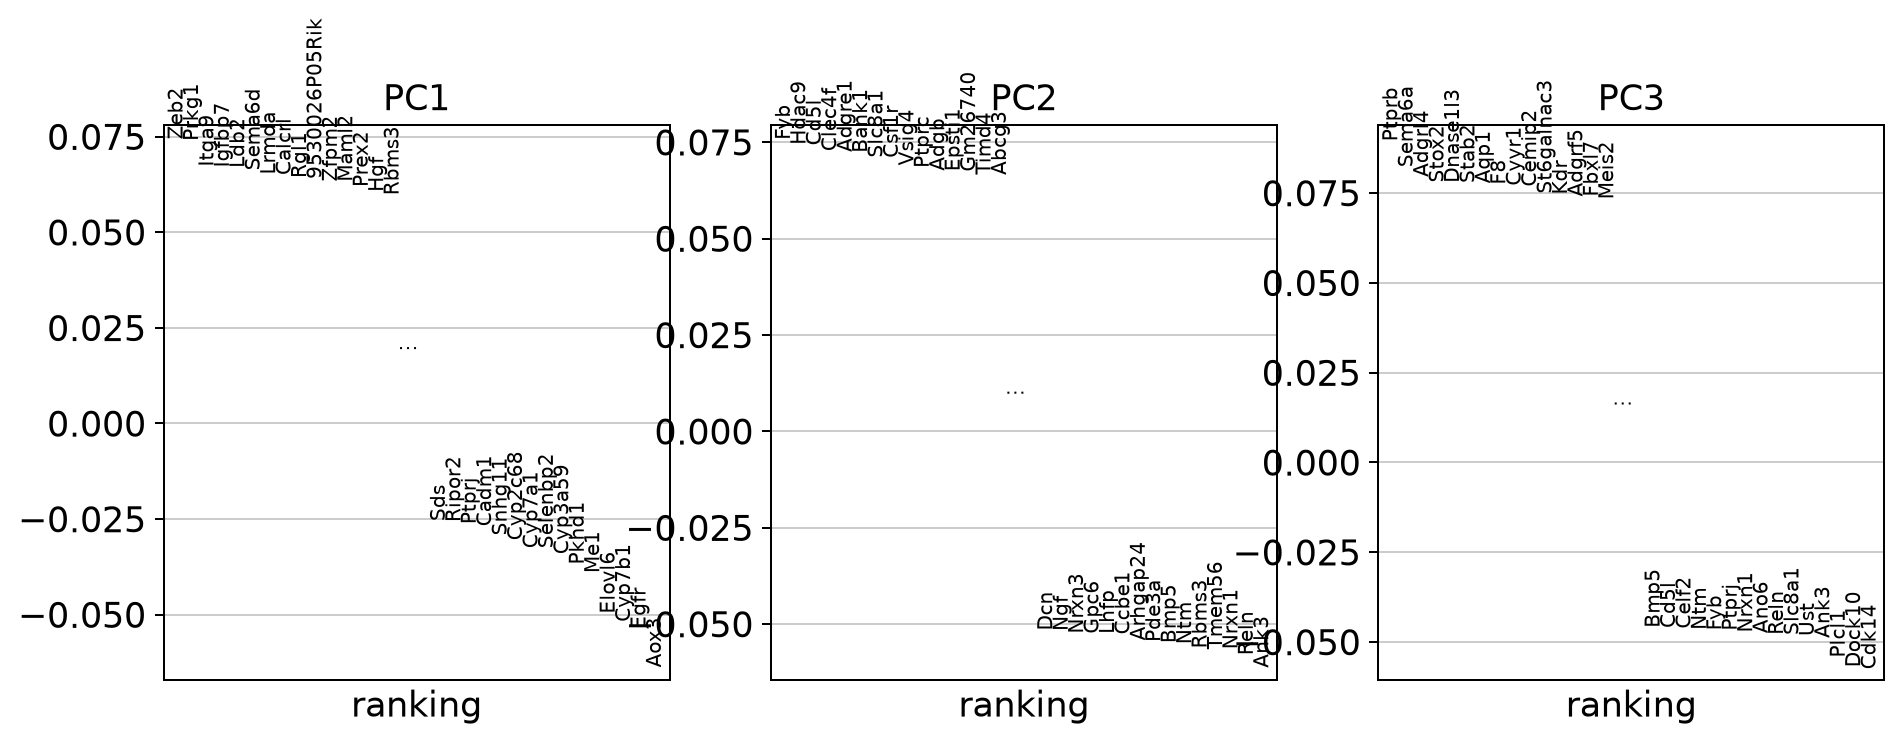

In [16]:
sc.pl.pca_loadings(adata_hvg, components=[1, 2, 3])

Genes with the largest positive and negative loadings are the strongest contributors to each PC. Some loadings include metabolic and liver-associated genes, suggesting that the components capture aspects of hepatic biology. These plots identify candidate genes and programs to investigate; a component cannot be confidently named from a handful of genes alone.

### Step 9: Construct the neighbor graph and UMAP

We construct a graph connecting transcriptomically similar nuclei in PCA space. UMAP visualizes this graph in two dimensions. UMAP is not a spatial map of the liver and distances between distant groups are not literal physical distances.

In [17]:
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg, random_state=42)

computing neighbors
    using 'X_pca' with n_pcs = 30


/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished (0:00:35)
computing UMAP
    finished (0:00:11)


Next we identify graph communities with Leiden, then color the UMAP by cluster label. These labels do not yet tell us which cell types are present.

running Leiden clustering
    finished (0:00:01)


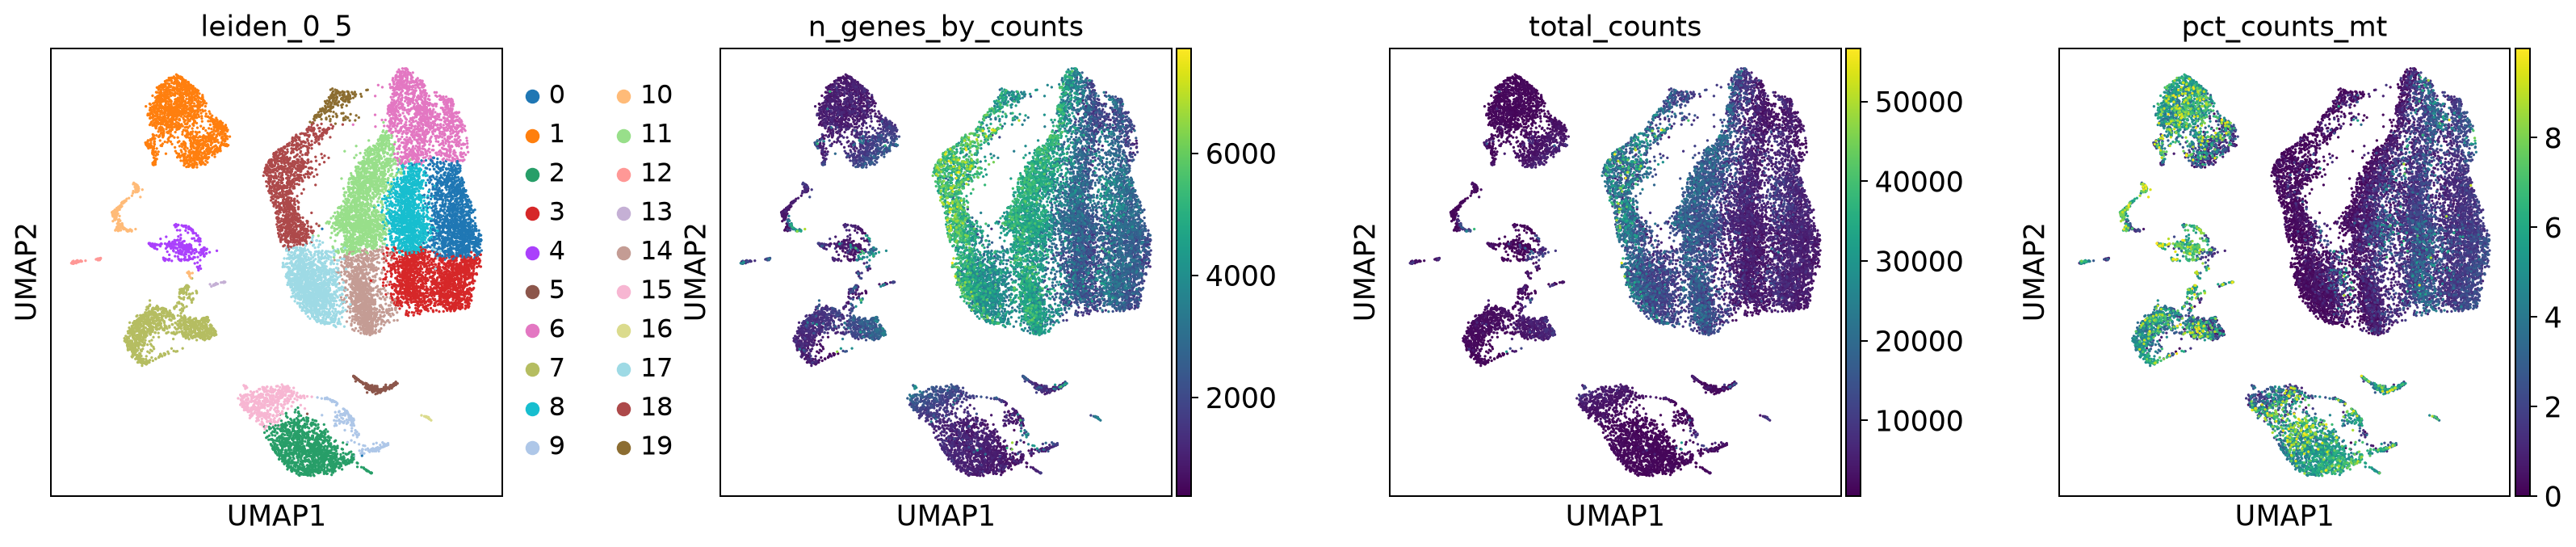

leiden_0_5
0     1398
1     1599
2     1271
3     1784
4      300
5      165
6     1367
7     1102
8     1235
9      190
10     173
11    1771
12      56
13      23
14    1066
15     505
16      22
17    1452
18    1221
19     200
Name: count, dtype: int64


In [18]:
sc.tl.leiden(adata_hvg, resolution=0.5, key_added="leiden_0_5", flavor="igraph", directed=False)
sc.pl.umap(adata_hvg, color=["leiden_0_5", "n_genes_by_counts", "total_counts", "pct_counts_mt"],
           wspace=0.35)
print(adata_hvg.obs["leiden_0_5"].value_counts().sort_index())

The embedding separates several smaller groups from a broad, connected population on the right. At resolution 0.5, Leiden identifies 20 clusters, but a cluster is not necessarily a distinct cell type. The connected right-hand populations may represent related hepatocyte states; several smaller islands may represent non-parenchymal cell types. The gene-count and UMI overlays reveal variation in library complexity across populations. We must use markers to identify the groups before making biological claims.

### Step 10: Check library-of-origin effects

Since we know each nucleus's library of origin, we can color the same UMAP coordinates by either Leiden cluster or library. If a transcriptional group is dominated by one library, its separation might partly reflect experimental variation rather than a distinct biological cell type. Conversely, seeing cells from several libraries in the same group supports reproducibility, although it does not rule out subtler batch effects.

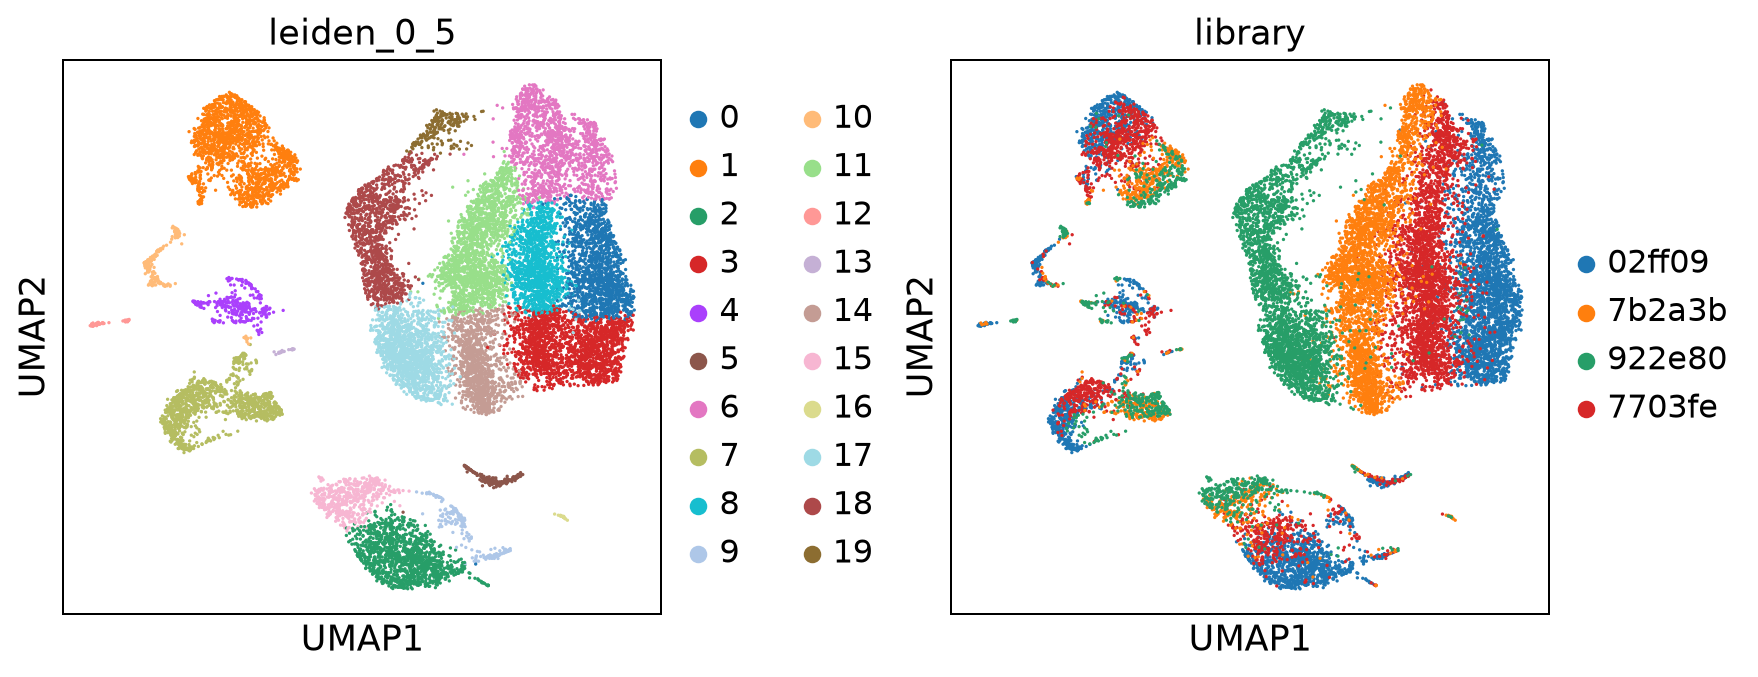

In [19]:
sc.pl.umap(
    adata_hvg,
    color=["leiden_0_5", "library"],
    wspace=0.35
)

The UMAP shows that several smaller cell populations contain nuclei from multiple libraries, whereas the large hepatocyte population exhibits partial separation by library of origin. This suggests that library-associated variation may contribute to the observed clustering. Therefore, clusters should be interpreted cautiously and biological identities should be supported by marker gene expression.

**Question:** If one Leiden cluster is dominated by a single library, what technical and biological explanations would you consider before naming it as a distinct cell type?

### Step 11: Explore Leiden clustering resolution

Leiden clustering identifies groups of transcriptionally similar nuclei using the nearest-neighbor graph. UMAP is used to visualize these groups in two dimensions, but the clustering itself is not performed on the UMAP coordinates.

running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)


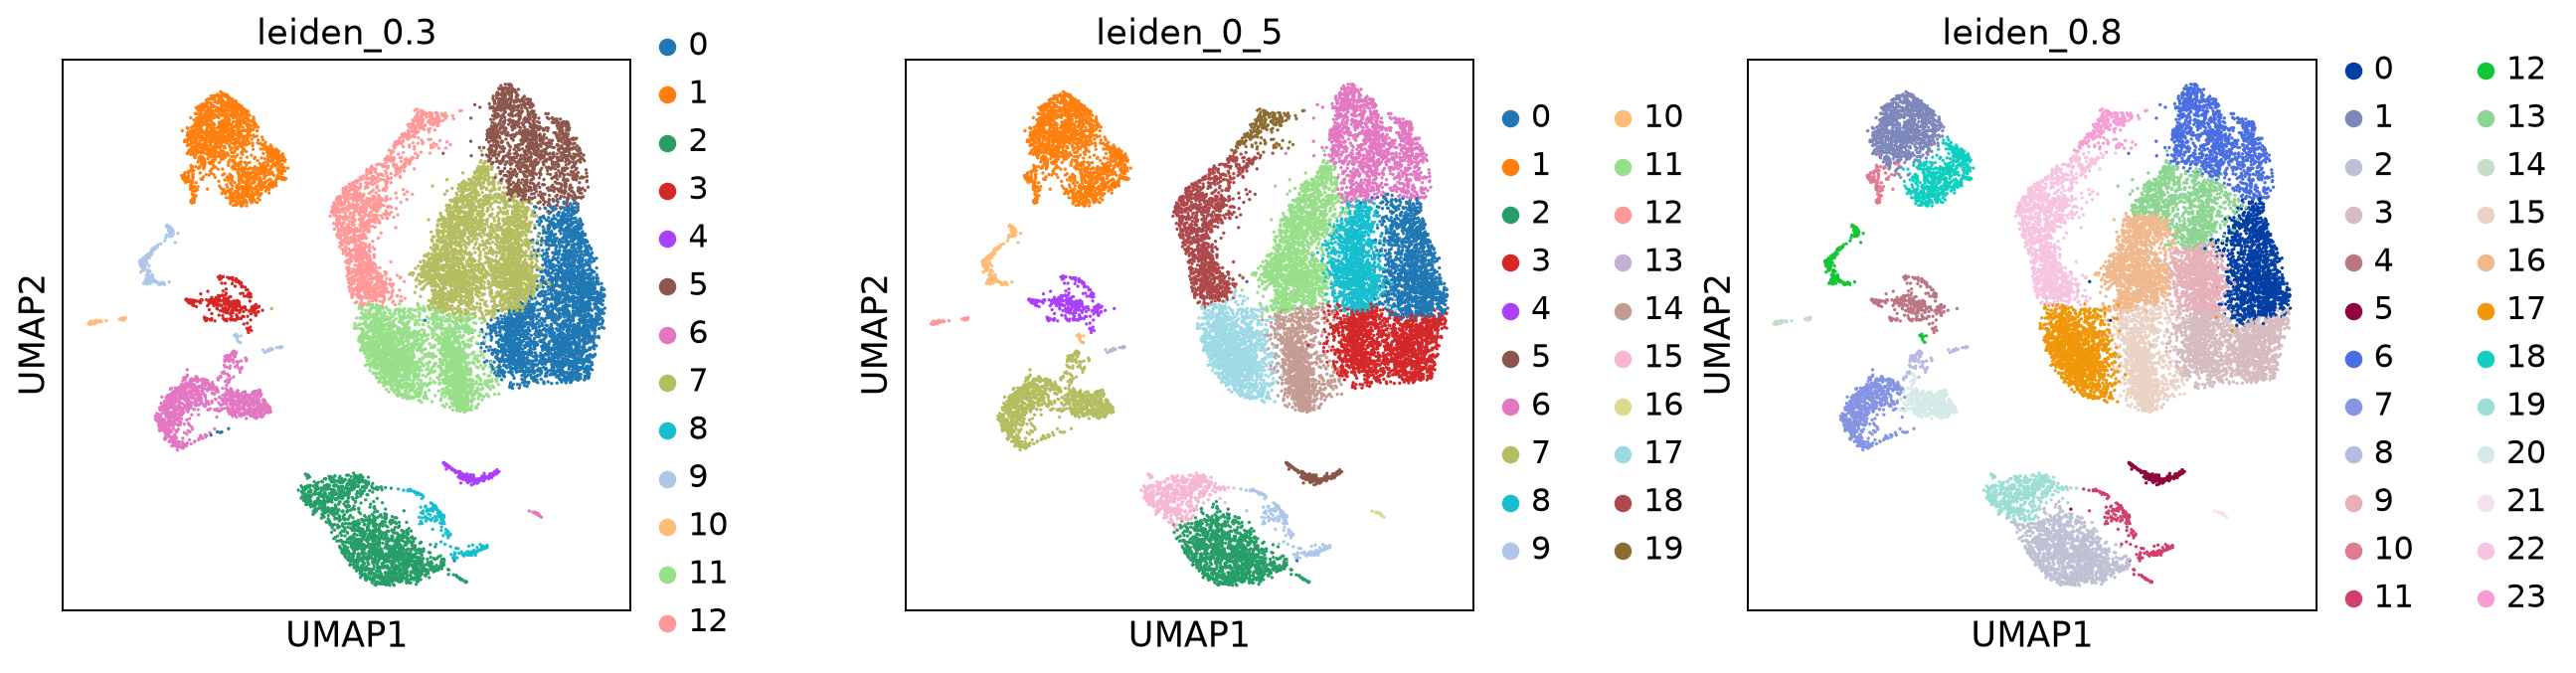

In [20]:
for resolution in [0.3, 0.8]:
    sc.tl.leiden(adata_hvg, resolution=resolution, key_added=f"leiden_{resolution}",
                 flavor="igraph", directed=False)
sc.pl.umap(adata_hvg, color=["leiden_0.3", "leiden_0_5", "leiden_0.8"], wspace=0.35)

Lower resolution (0.3) combines more neighboring cells into broad communities, whereas higher resolution (0.8) divides some of them further. The overall geometry stays unchanged because we are recoloring the same UMAP. Changes in cluster number alone are not evidence of new biological cell types. We use 0.5 as an exploratory starting resolution and can revisit it after marker analysis. 

**Question:** How does changing Leiden resolution alter the number of clusters without changing the underlying UMAP coordinates?

### Step 12: Identify cluster marker genes

We compare each Leiden cluster with the remaining nuclei using the Wilcoxon test. These are exploratory cluster markers, not replicate-aware differential-expression statistics. Individual nuclei from the same mouse are not independent replicates.

In [21]:
# Carry the embedding and Leiden labels into full-gene, log-normalized adata.
adata.obsm["X_umap"] = adata_hvg.obsm["X_umap"].copy()
for col in ["leiden_0.3", "leiden_0_5", "leiden_0.8"]:
    adata.obs[col] = adata_hvg.obs[col].copy()

Now rank genes for each cluster and inspect the strongest candidate markers.

ranking genes
    finished (0:00:12)


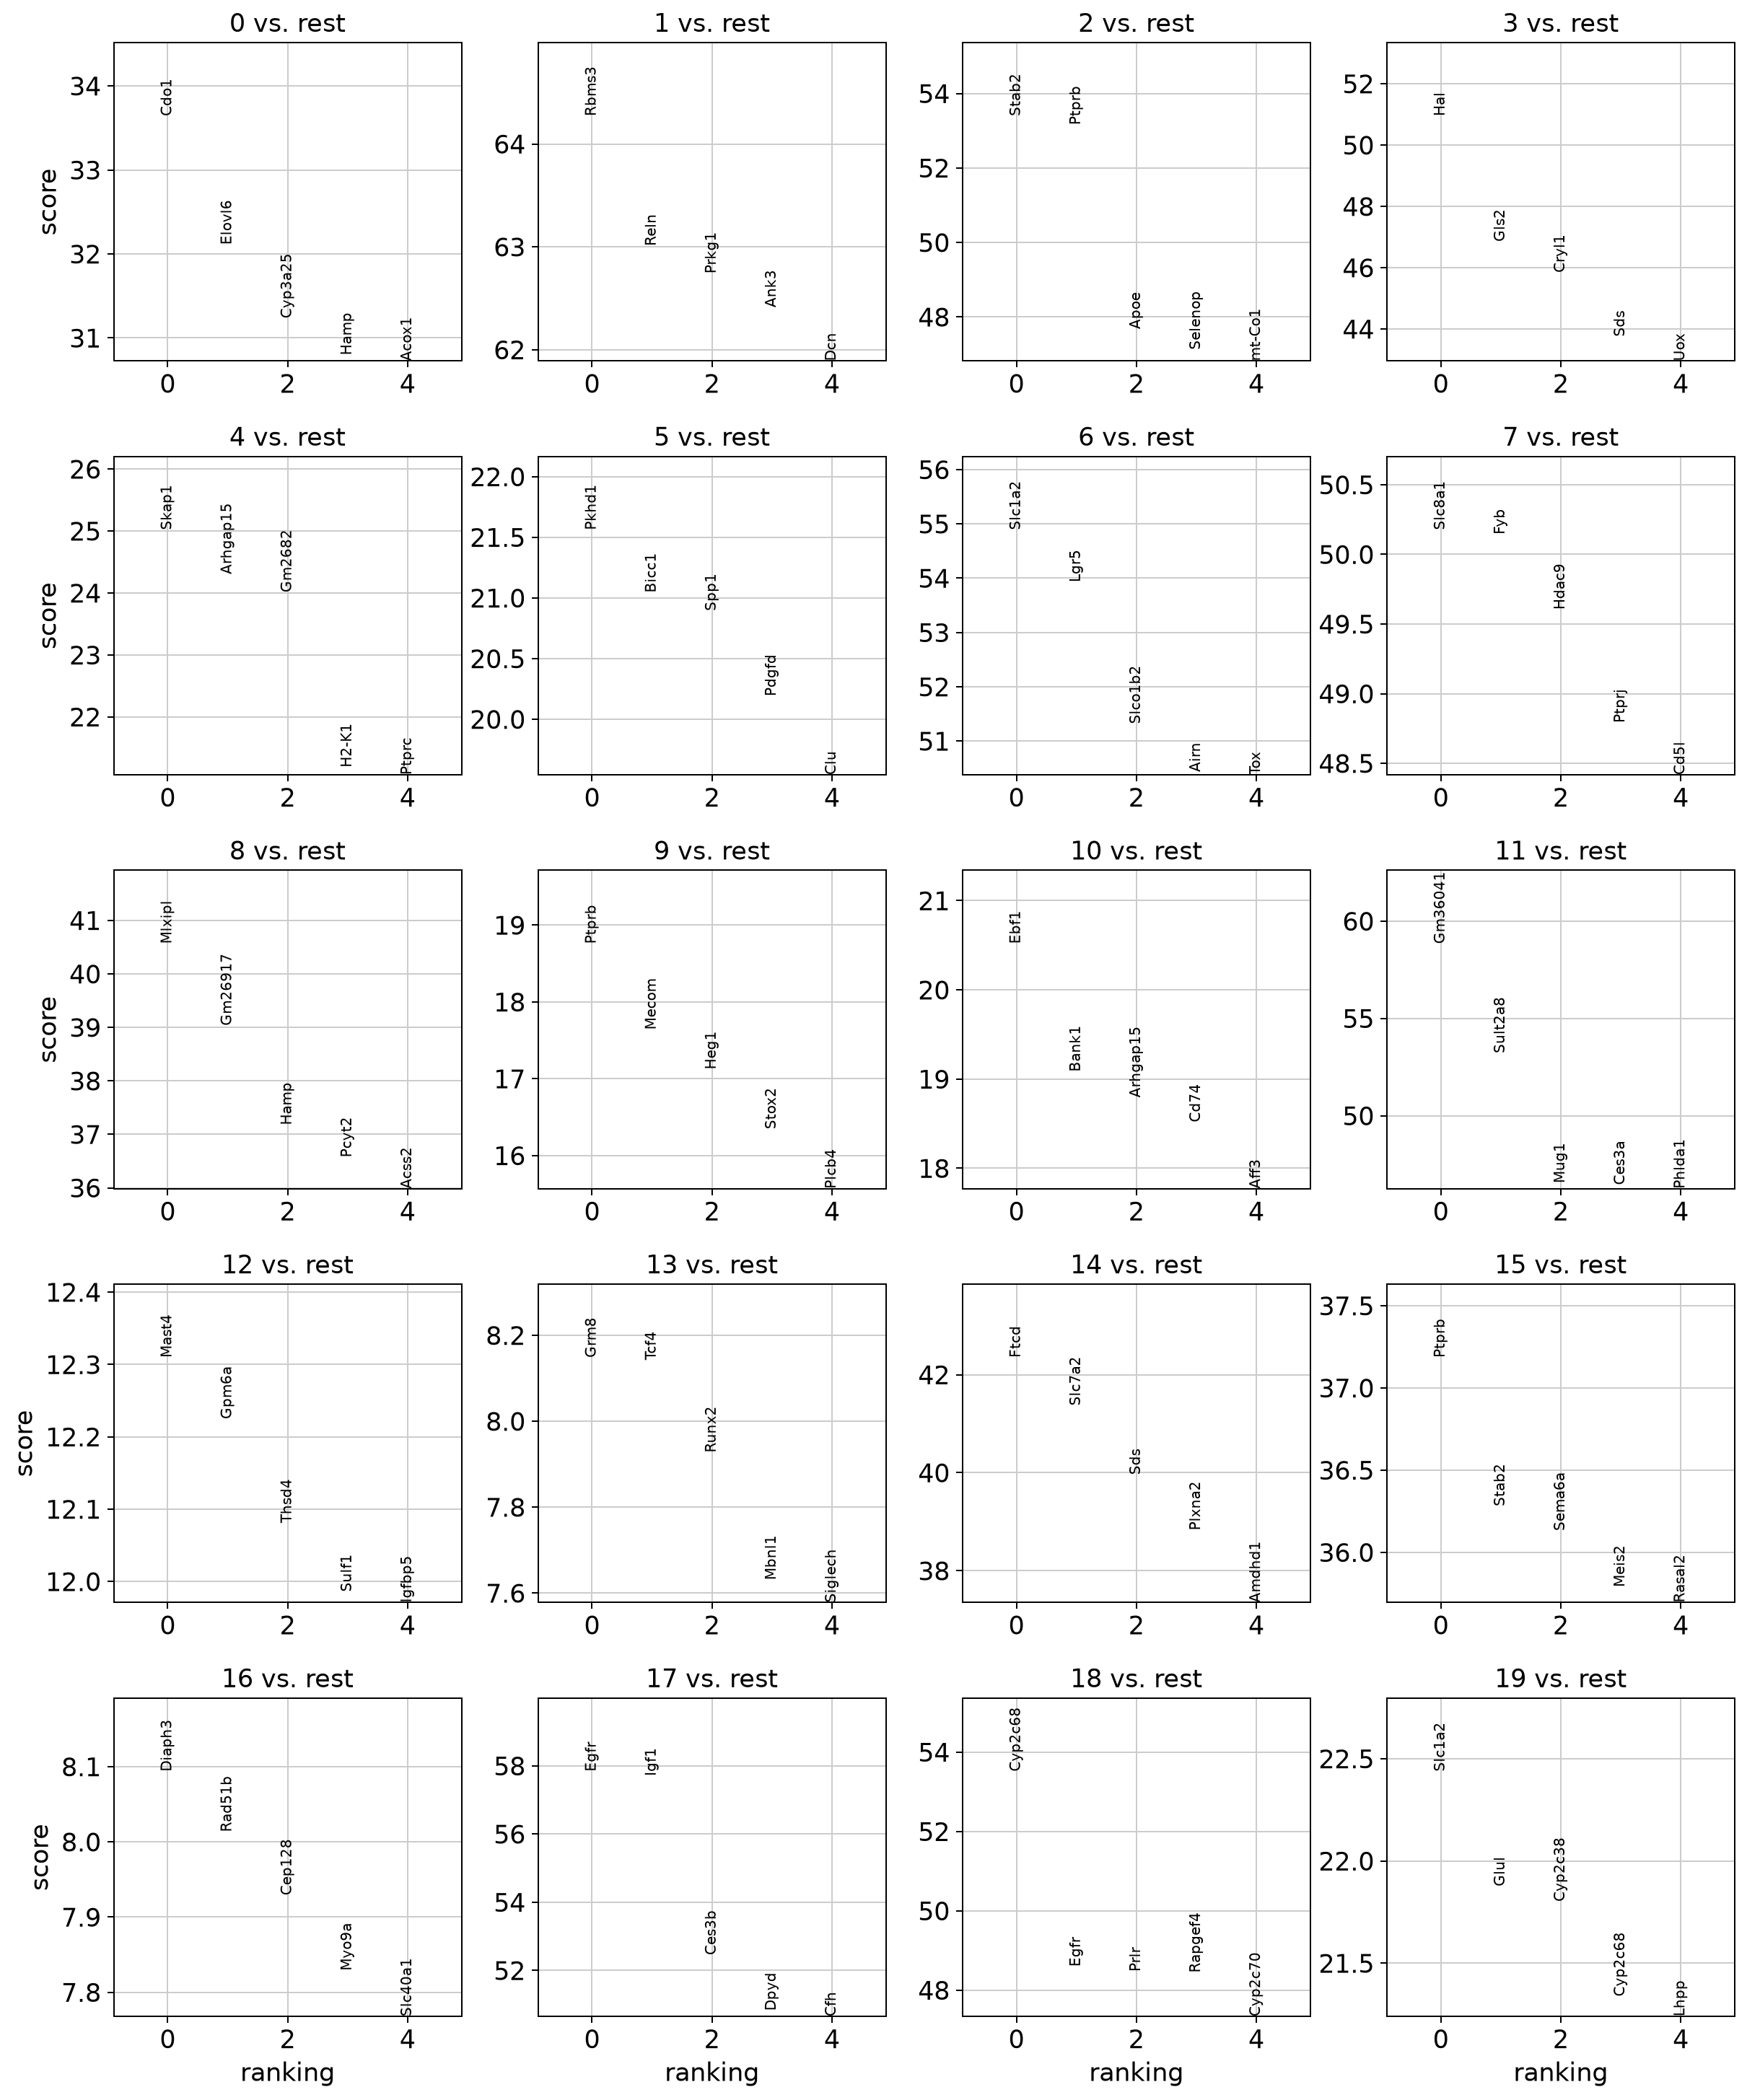

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,0,Cdo1,33.640472,1.480256,4.297285e-248,8.857133e-244,0.979971,0.807638
1,0,Elovl6,32.109627,1.788414,3.235565e-226,3.334412e-222,0.913448,0.622629
2,0,Cyp3a25,31.234222,1.551133,3.656695e-214,2.512272e-210,0.998569,0.826990
3,0,Hamp,30.795191,1.790084,3.039321e-208,1.566086e-204,0.986409,0.782028
4,0,Acox1,30.726160,1.148009,2.546399e-207,1.049677e-203,0.984263,0.826861
5,0,Me1,30.645815,1.709862,3.004729e-206,1.032174e-202,0.904864,0.605664
6,0,Acss2,30.171186,1.654851,5.657620e-200,1.665846e-196,0.957797,0.695588
7,0,Slco1b2,29.648050,1.601960,3.593554e-193,9.258344e-190,0.992847,0.810928
8,0,Scd1,29.319345,1.387911,5.878940e-189,1.346343e-185,0.992132,0.849761
9,0,Abcc2,29.205280,1.633668,1.661777e-187,3.425089e-184,0.994278,0.725777


In [22]:
sc.tl.rank_genes_groups(adata, groupby="leiden_0_5", method="wilcoxon",
                       use_raw=True, pts=True)
sc.pl.rank_genes_groups(adata, n_genes=5, sharey=False)
marker_table = sc.get.rank_genes_groups_df(adata, group=None)
display(marker_table.head(20))

Different Leiden clusters show different highly ranked genes, confirming transcriptional differences. For example, several clusters rank liver-metabolic genes highly, whereas others are associated with endothelial, immune or biliary markers. The Wilcoxon analysis is useful for marker discovery, but because nuclei are not independent biological replicates it is not appropriate as a mouse-level differential-expression analysis.

A dotplot summarizes both the fraction of nuclei expressing a marker (dot size) and its average expression (color). 

{'Hepatocyte': ['Alb', 'Apoa1', 'Ttr'], 'Endothelial': ['Pecam1', 'Kdr', 'Stab2', 'Lyve1'], 'Kupffer/myeloid': ['Adgre1', 'C1qa', 'Clec4f', 'Lyz2'], 'Stellate': ['Lrat', 'Rgs5', 'Des'], 'Biliary': ['Krt19', 'Epcam', 'Sox9'], 'T cell': ['Cd3d', 'Cd3e'], 'B cell': ['Cd79a', 'Ms4a1']}


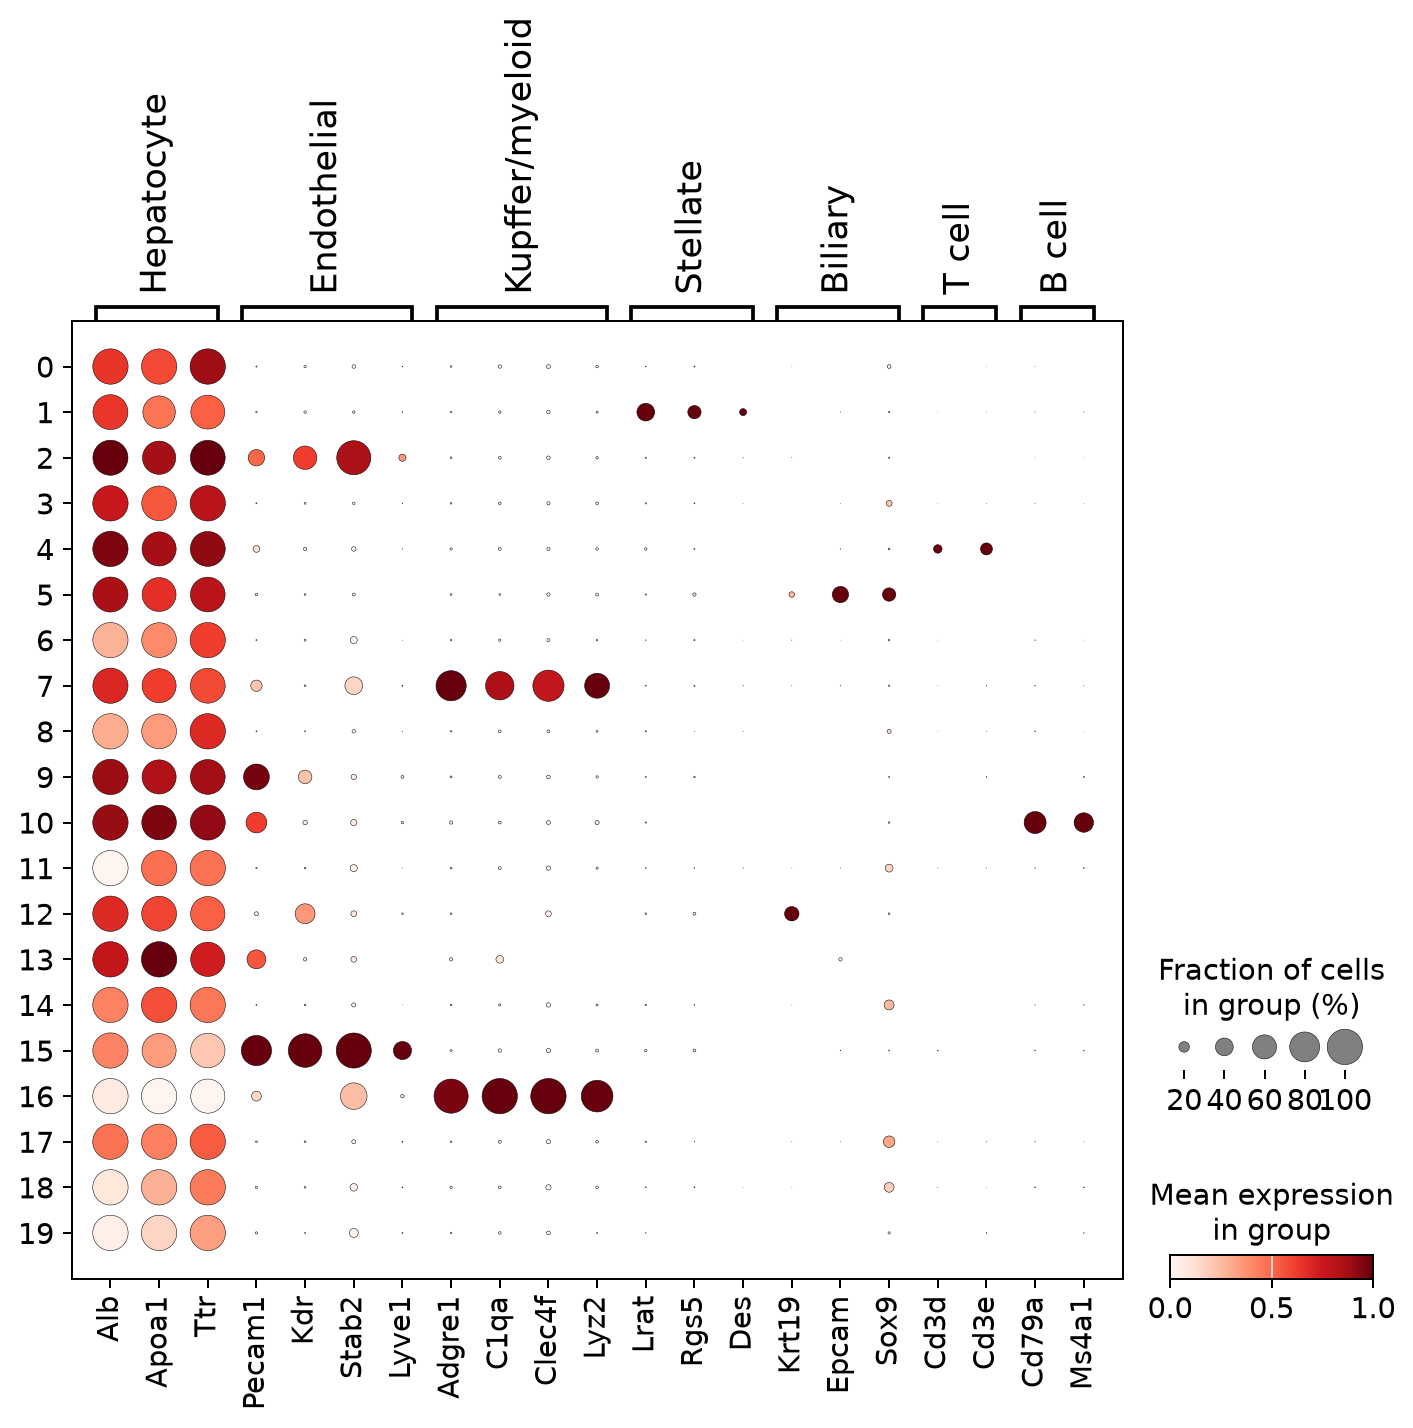

In [23]:
markers = {
    "Hepatocyte": ["Alb", "Apoa1", "Ttr"],
    "Endothelial": ["Pecam1", "Kdr", "Stab2", "Lyve1"],
    "Kupffer/myeloid": ["Adgre1", "C1qa", "Clec4f", "Lyz2"],
    "Stellate": ["Lrat", "Rgs5", "Des"],
    "Biliary": ["Krt19", "Epcam", "Sox9"],
    "T cell": ["Cd3d", "Cd3e"],
    "B cell": ["Cd79a", "Ms4a1"],
}
markers_available = {k: [g for g in genes if g in adata.var_names]
                     for k, genes in markers.items()}
markers_available = {k: genes for k, genes in markers_available.items() if genes}
print(markers_available)
sc.pl.dotplot(adata, markers_available, groupby="leiden_0_5", use_raw=True,
              standard_scale="var")

The expected marker combinations are visible: clusters 4 (Cd3d/Cd3e, T cells), 10 (Cd79a/Ms4a1, B cells), 7 (Adgre1/C1qa/Clec4f/Lyz2, Kupffer/myeloid), 5 (Epcam/Sox9, biliary), 1 (Lrat/Rgs5, stellate-like), and 2/15 (Pecam1/Kdr/Stab2, endothelial-like). These assignments are provisional and should be checked against each cluster's full marker list. Alb, Apoa1 and Ttr appear in many clusters, including some expressing non-hepatocyte markers, so their detection alone cannot define hepatocytes. Ambient hepatocyte RNA, mixed profiles and other biological or technical factors are possible explanations. Many of the remaining larger groups are hepatocyte candidates, potentially reflecting different zonation states.

### Step 13: Annotate liver cell types

Use multiple established liver markers to assign provisional biological identities. Cluster numbers are arbitrary and can vary with parameters. Leave ambiguous clusters Unassigned until there is enough evidence.

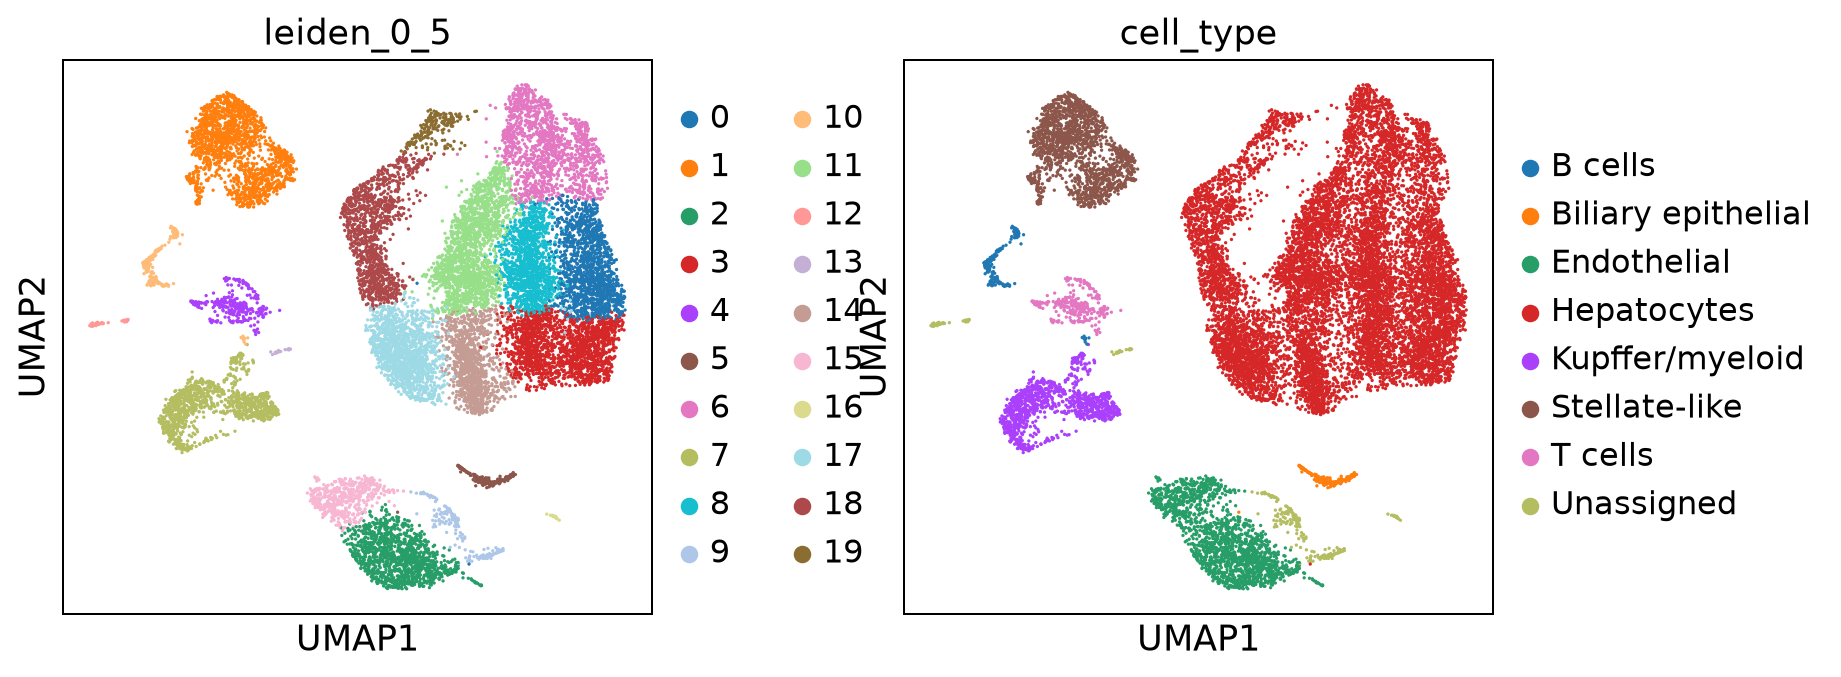

In [24]:

cluster_to_celltype = {
    # Hepatocytes
    "0": "Hepatocytes",
    "3": "Hepatocytes",
    "6": "Hepatocytes",
    "8": "Hepatocytes",
    "11": "Hepatocytes",
    "14": "Hepatocytes",
    "17": "Hepatocytes",
    "18": "Hepatocytes",
    "19": "Hepatocytes",

    # Non-parenchymal populations
    "1": "Stellate-like",
    "2": "Endothelial",
    "4": "T cells",
    "5": "Biliary epithelial",
    "7": "Kupffer/myeloid",
    "10": "B cells",
    "15": "Endothelial",
}

adata.obs["cell_type"] = (
    adata.obs["leiden_0_5"].astype(str)
    .map(cluster_to_celltype)
    .fillna("Unassigned")
    .astype("category")
)
sc.pl.umap(adata, color=["leiden_0_5", "cell_type"], wspace=0.3)

The Leiden clustering identifies distinct transcriptional populations within the mouse liver. Based on the expression of known marker genes, these clusters can be annotated into major liver cell types, including hepatocytes, endothelial cells, Kupffer/myeloid cells, hepatic stellate cells, biliary epithelial cells, T cells and B cells.

Hepatocytes represent the largest population and are distributed across multiple Leiden clusters, suggesting transcriptional heterogeneity within this cell type. This is consistent with the presence of distinct hepatocyte states, potentially associated with liver zonation. The remaining cell types form relatively well-separated populations, reflecting their distinct transcriptional profiles.

A few small clusters remain unassigned because their identity could not be confidently determined from the selected markers.

**Question:** Which marker combinations support a hepatocyte, endothelial or Kupffer-cell assignment? Why is a single marker sometimes insufficient?

## Part 3: Investigate hepatocyte zonation and save the analysis

### Step 14: Examine hepatocyte zonation markers

The liver has a continuous periportal–pericentral axis. Glul is enriched pericentrally, Cyp2e1 in pericentral/intermediate hepatocytes and Cps1 toward periportal zones. Expression on a UMAP can suggest this gradient but only spatial data can establish tissue location.

Plot zonation genes on the UMAP. Remember that UMAP coordinates are **not** spatial coordinates.

Available zonation genes: ['Glul', 'Cyp2e1', 'Cps1', 'Sds']


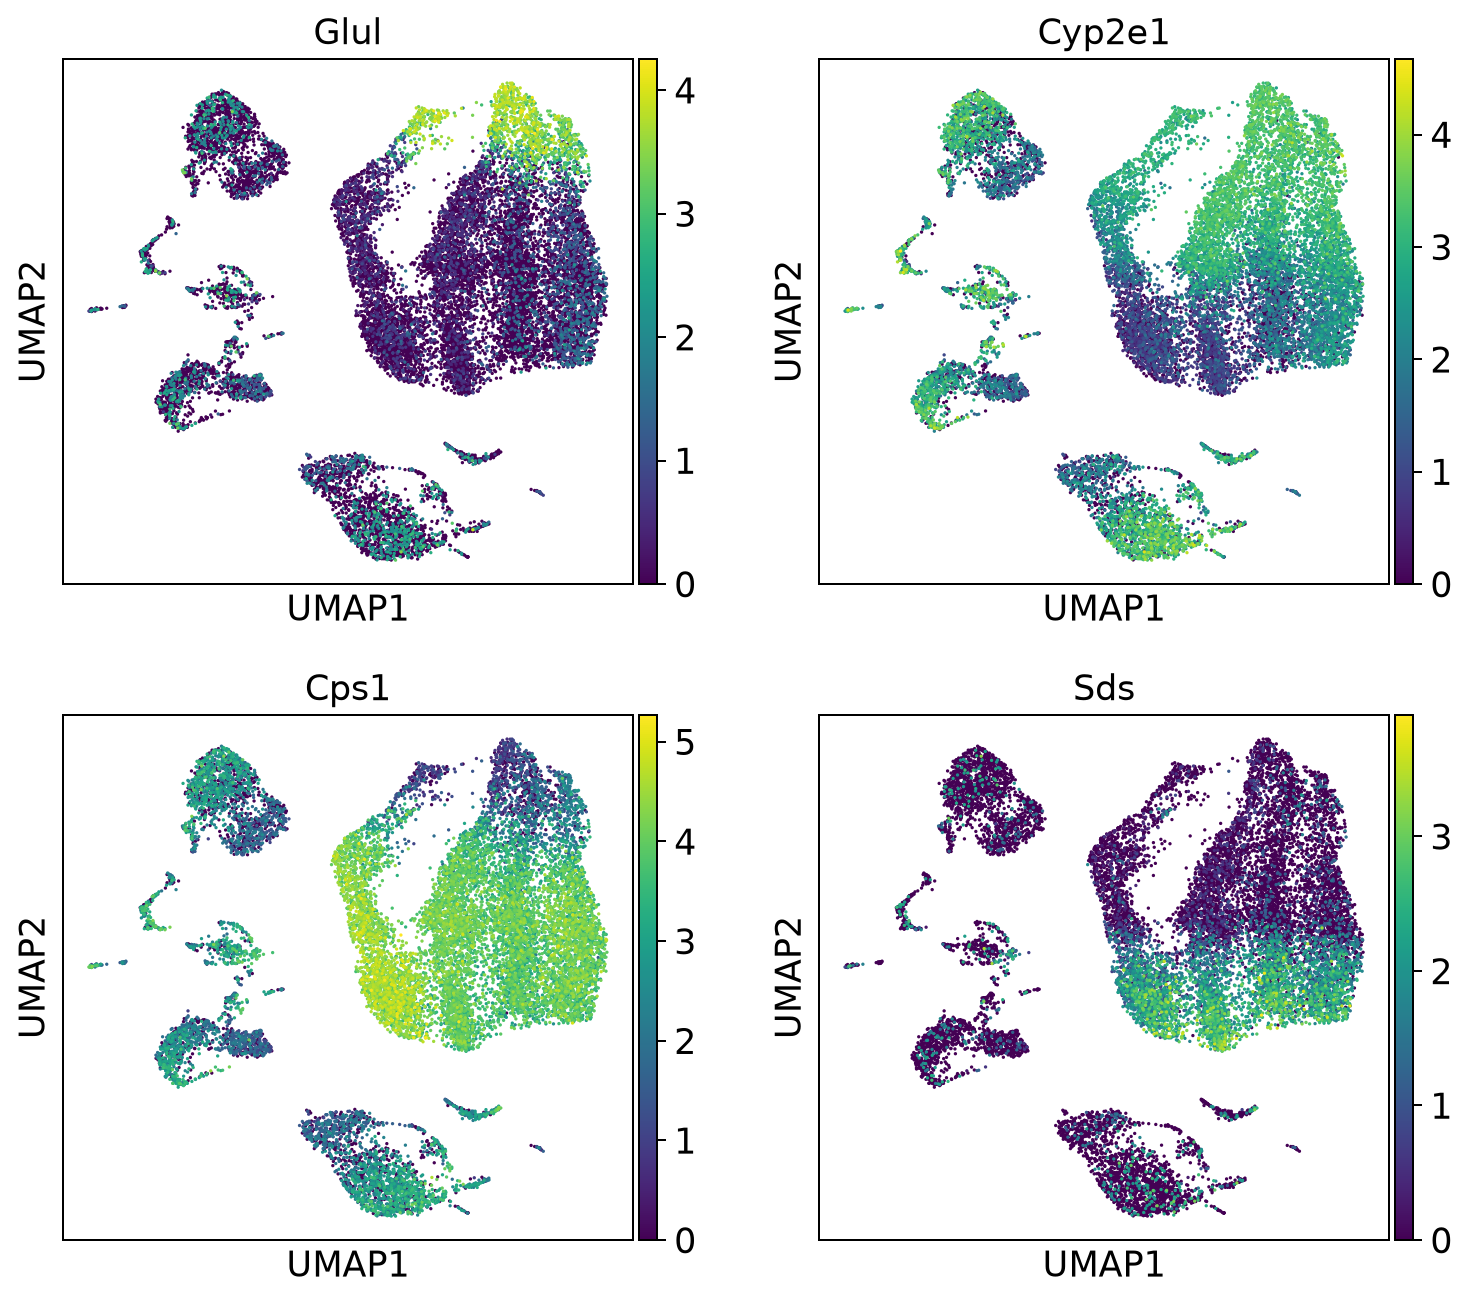

In [25]:
zonation_genes = [g for g in ["Glul", "Cyp2e1", "Cps1", "Sds"]
                  if g in adata.var_names]
print("Available zonation genes:", zonation_genes)
if zonation_genes:
    sc.pl.umap(adata, color=zonation_genes, cmap="viridis", ncols=2,
               use_raw=True)

Glul is concentrated in a subset of the large right-hand population, whereas Cps1 is more widely expressed with an approximately opposing pattern. Cyp2e1 shows a broader distribution, and Sds is enriched toward part of the lower/right region. These overlapping gradients are compatible with hepatocyte zonation, but the embedding contains multiple cell populations and is not a spatial tissue map. The smFISH and Visium practicals will allow us to examine where these expression patterns occur in liver tissue.

**Question:** What can the patterns of *Glul*, *Cyp2e1* and *Cps1* suggest about hepatocyte zonation, and what important information is absent from a UMAP?

### Step 15: Reanalyze hepatocytes separately

Hepatocytes are the most abundant cell population in this dataset, but they were assigned to several different Leiden clusters in the full-liver analysis. This is not necessarily a problem: cells of the same broad type may perform different functions and occupy different transcriptional states.

To study this variation in more detail, we will select only the nuclei provisionally annotated as hepatocytes and repeat the steps used to construct the transcriptomic embedding. Removing the much larger differences between hepatocytes and other liver cell types may make subtler hepatocyte-specific variation easier to detect.

Our biological question is whether some of this heterogeneity is compatible with liver zonation, the gradual specialization of hepatocytes along the periportal–pericentral axis.

### Recomputing the hepatocyte embedding and clusters

The code below carries out six steps:
1. **Subset hepatocytes.** Keep only nuclei with the provisional annotation Hepatocytes.
2. **Select highly variable genes again.** Genes that distinguish different liver cell types are not necessarily the most informative genes within hepatocytes. We therefore select 1,500 HVGs from this subset.
3. **Scale expression and perform PCA.** Standardize the selected genes and summarize their major patterns of variation in principal components.
4. **Construct a new nearest-neighbor graph.** Identify related hepatocytes using the first 20 PCs and 15 neighbors per nucleus.
5. **Calculate a new UMAP.** Display relationships within hepatocytes rather than relying on coordinates learned from the complete liver dataset.
6. **Run Leiden clustering.** Identify graph communities at resolution 0.3, a deliberately exploratory choice.
We do not normalize or log-transform the counts a second time because the subset inherits the normalized, log-transformed expression matrix from the earlier analysis. The new clusters describe transcriptional similarity; they are not predefined anatomical zones.

Number of hepatocytes: 11494
extracting highly variable genes
    finished (0:00:00)
computing PCA
    with n_comps=30


/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 20
    finished (0:00:01)
computing UMAP
    finished (0:00:07)
running Leiden clustering
    finished (0:00:00)


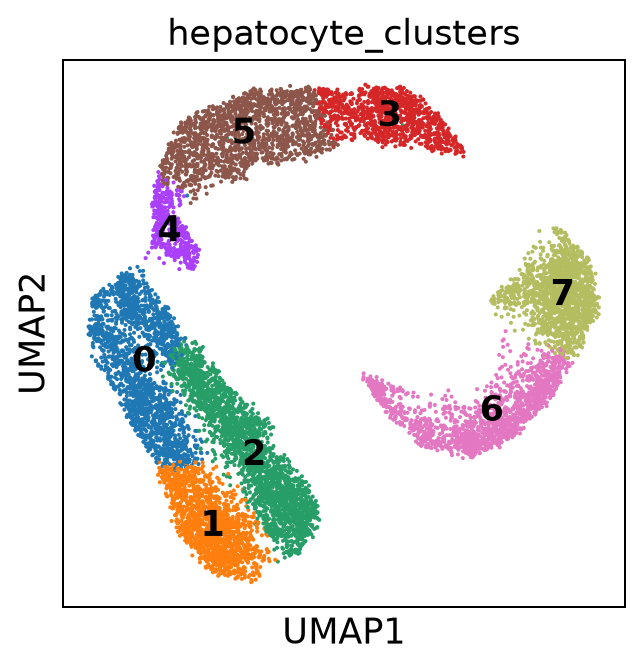

In [26]:
# Subset hepatocytes
hep = adata[adata.obs["cell_type"] == "Hepatocytes"].copy()

print(f"Number of hepatocytes: {hep.n_obs}")

# Identify highly variable genes
sc.pp.highly_variable_genes(
    hep,
    n_top_genes=1500,
    flavor="seurat"
)

hep_sub = hep[:, hep.var["highly_variable"]].copy()

# PCA
sc.pp.scale(hep_sub, max_value=10)
sc.pp.pca(hep_sub, n_comps=30)

# Nearest-neighbor graph
sc.pp.neighbors(hep_sub, n_neighbors=15, n_pcs=20)

# UMAP
sc.tl.umap(hep_sub, random_state=42)

# Leiden clustering
sc.tl.leiden(
    hep_sub,
    resolution=0.3,
    key_added="hepatocyte_clusters",
    flavor="igraph",
    directed=False
)

# Visualize hepatocyte clusters
sc.pl.umap(
    hep_sub,
    color="hepatocyte_clusters",
    legend_loc="on data"
)

The subset contains 11,494 hepatocyte nuclei. Their new UMAP shows several connected groups, and Leiden clustering at resolution 0.3 identifies eight clusters (0–7). Thus, hepatocytes are not transcriptionally identical, even after the other liver cell types have been excluded.

Most clusters occupy a broadly connected part of the embedding, but clusters 6 and 7 form a more separated group on the right. This separation could reflect a distinct hepatocyte program, differences between sequencing libraries or residual technical variation. We cannot determine the cause from UMAP geometry alone.

Important: Leiden clusters are computational groups, not direct measurements of liver zones. We next inspect genes with known zonation-associated expression patterns to give these groups a biological interpretation.

#### Visualizing zonation-associated gene expression

In a liver lobule, hepatocytes near portal tracts and central veins carry out different metabolic functions. We now overlay four example genes on the hepatocyte-only UMAP:
- **Glul** is enriched in pericentral hepatocytes.
- **Cyp2e1** is associated with pericentral/intermediate hepatocyte metabolism.
- **Cps1** is associated with periportal functions.
- **Sds** illustrates additional spatially variable metabolic expression.
The plots use use_raw=True. Here, .raw contains the earlier log-normalized expression values for all genes, including genes that were not selected as HVGs. This lets us visualize marker expression without restricting ourselves to the 1,500 genes used for PCA and clustering.

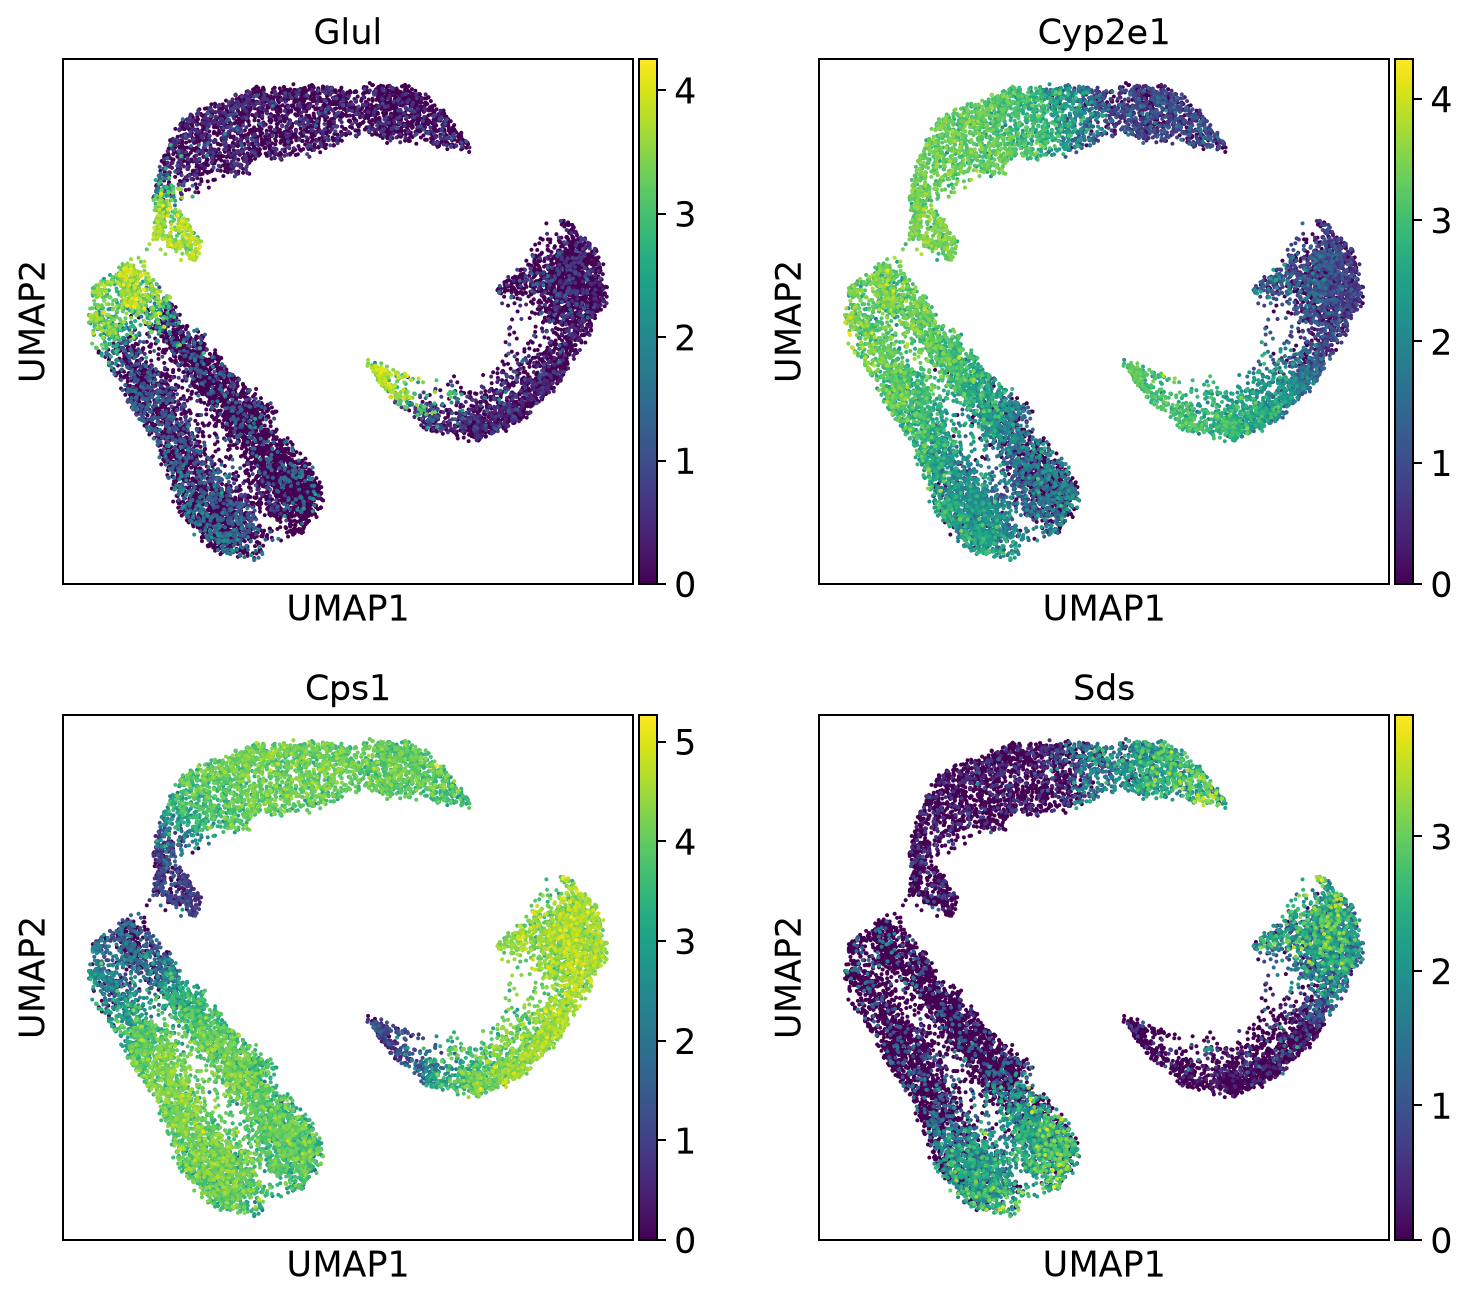

In [27]:
sc.pl.umap(
    hep_sub,
    color=["Glul", "Cyp2e1", "Cps1", "Sds"],
    use_raw=True,
    cmap="viridis",
    ncols=2
)

The hepatocyte-only embedding reveals heterogeneous and partially overlapping gene-expression patterns:

- **Glul** has relatively localized expression, consistent with enrichment in a restricted pericentral-associated hepatocyte program.
- **Cyp2e1** is detected across a broader part of the embedding, with variable expression between regions.
- **Cps1** is more widespread and is relatively stronger in regions with weaker Glul expression, although the patterns are not perfectly mutually exclusive.
- **Sds** shows a patchier distribution, illustrating that individual metabolic genes do not necessarily follow the same simple two-zone pattern.

Taken together, these plots are compatible with transcriptional variation associated with liver zonation, but they do not establish a single continuous anatomical trajectory. Some differences may reflect additional metabolic states, library effects or other biological variation. In particular, the more separated clusters 6 and 7 require further investigation before assigning them a spatial identity.

A UMAP is not a tissue map. Close points have similar transcriptomes, not necessarily neighboring positions in a liver lobule. Spatial smFISH or Visium data would be needed to locate these expression programs relative to portal tracts and central veins.

#### Optional check: do the separated groups differ in sequencing quality?

Before interpreting the separated hepatocyte groups as distinct biology, compare their QC characteristics. For example, a cluster with unusually low numbers of detected genes might be influenced by capture quality. The annotations and QC measurements from the original AnnData object are retained in the hepatocyte subset.

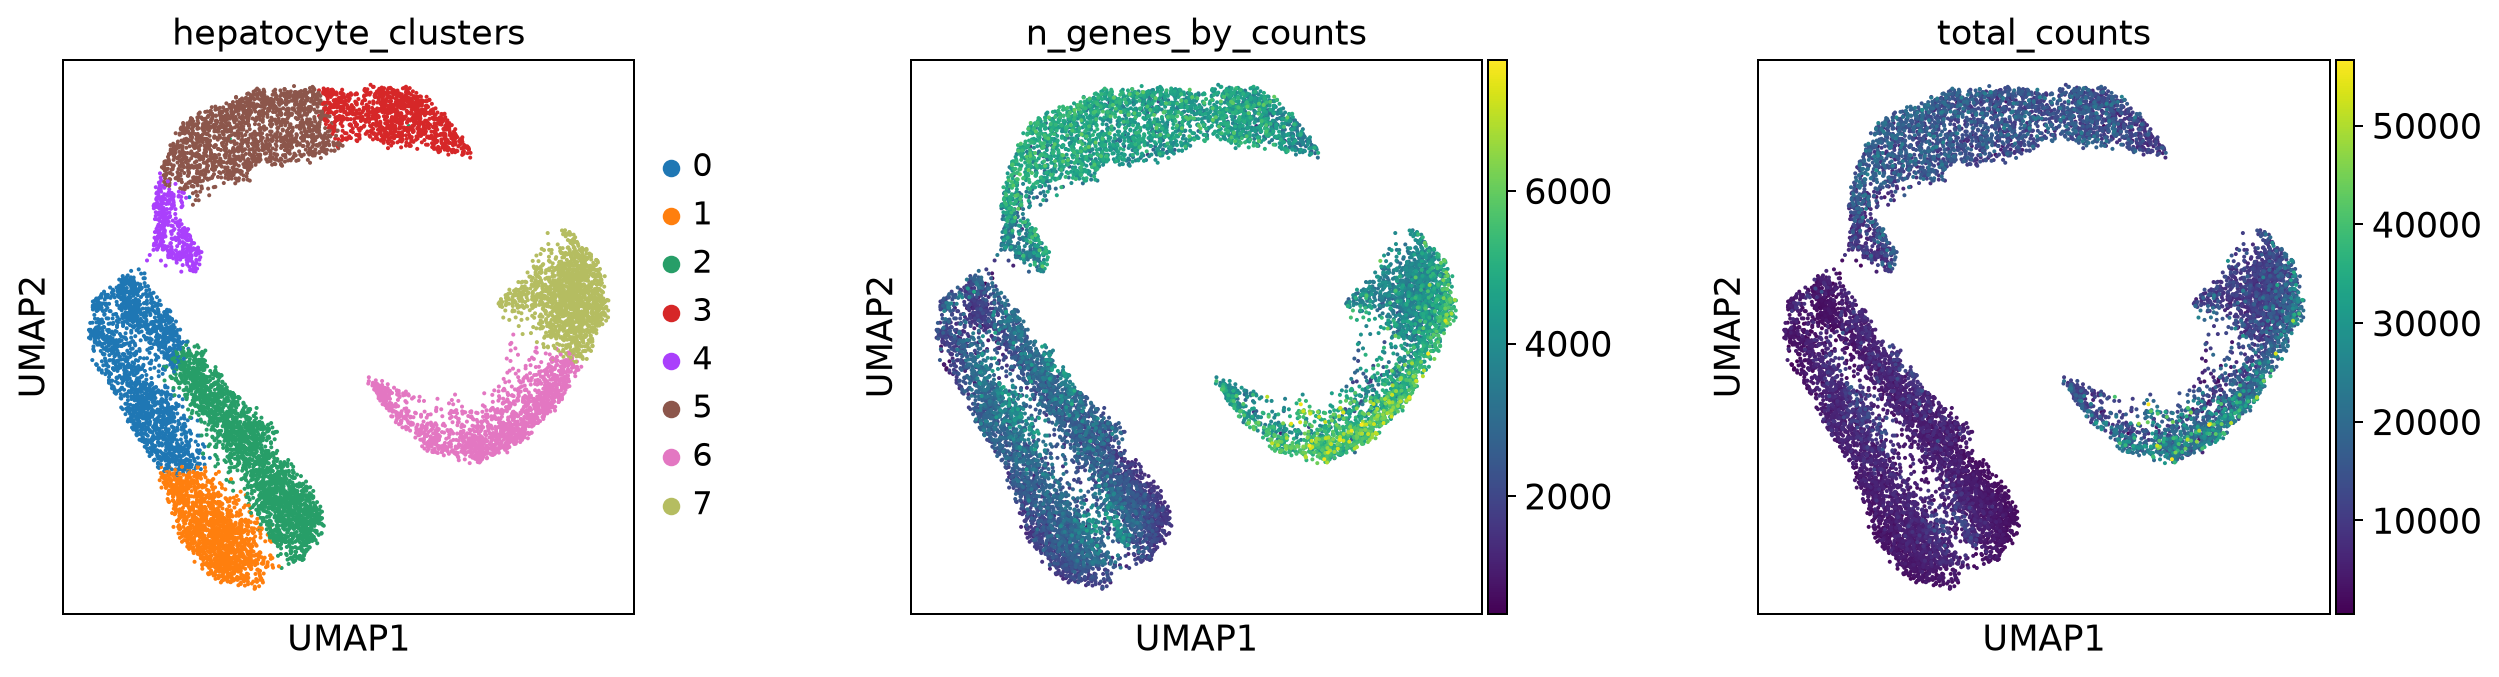

In [28]:
sc.pl.umap(
    hep_sub,
    color=["hepatocyte_clusters", "n_genes_by_counts", "total_counts"],
    wspace=0.35
)

The QC plots reveal differences in the number of detected genes and total UMI counts across the hepatocyte population. In particular, the more separated clusters 6 and 7 generally exhibit higher transcript counts and gene detection than several other clusters.

This suggests that differences in sequencing depth, RNA content or other technical and biological factors could contribute to the observed transcriptional separation.

Therefore, although the zonation markers suggest biologically meaningful heterogeneity, we cannot assume that every Leiden cluster represents a distinct hepatocyte state or anatomical zone. Additional marker analysis and spatial validation would be needed to distinguish these possibilities.

**Question:** The separated hepatocyte clusters differ in total counts. How could you test whether the separation represents biology, library effects or sequencing-depth variation?

### Step 16: Save the results

Finally, save the analyzed objects as .h5ad files. The first contains the complete liver dataset, including QC metrics, normalized counts, the original UMAP and the provisional cell-type annotations. The second contains the hepatocyte-only analysis, including its own PCA, UMAP and Leiden clusters.

Keeping these results allows us to reopen the analyses without repeating the more expensive preprocessing steps. In hep_sub, the working .X matrix contains scaled HVGs, while .raw provides the full log-normalized gene space for marker plots.

In [29]:
output_file = RESULTS / "liver_scrna_scanpy_processed.h5ad"
adata.write_h5ad(output_file, compression="gzip")
print("Saved:", output_file)

Saved: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/results/scrna_liver/liver_scrna_scanpy_processed.h5ad


The hepatocyte-specific coordinates and clusters belong to hep_sub, not adata, so save that object separately as well.

In [30]:
hepatocyte_output_file = RESULTS / "liver_hepatocytes_processed.h5ad"
hep_sub.write_h5ad(hepatocyte_output_file, compression="gzip")
print("Saved:", hepatocyte_output_file)

Saved: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/results/scrna_liver/liver_hepatocytes_processed.h5ad


## Conclusion

1. **QC and preprocessing:** Gene and UMI count distributions help us evaluate nuclei, but thresholds depend on the assay and on upstream filtering. Normalization makes count depth more comparable and the original UMI counts remain available in `adata.layers["counts"]`.
2. **Cell identities:** PCA, neighbors, UMAP and Leiden clustering reveal transcriptionally distinct groups. Their identities require multiple marker genes, and apparent clusters may also be influenced by library origin and other technical factors.
3. **Hepatocyte heterogeneity:** A hepatocyte-only analysis reveals variation associated with metabolic zonation. Because nuclei were dissociated from their original positions, the UMAP cannot by itself locate cells along the portal–central axis.

## Exercises

1. **QC thresholds.** Change `MIN_GENES` from 350 to 500 or lower `MAX_MT` from 10 to 5. How many nuclei remain? Which distributions should you compare before choosing a cutoff? Start from the cached raw AnnData if you change QC parameters.
2. **HVGs and PCA.** Change the number of highly variable genes (for example, 1,000 versus 2,000). Does the broad UMAP structure change? Which PCA loadings could explain the difference?
3. **Leiden resolution.** Compare resolutions 0.3, 0.5 and 0.8. Does a higher resolution always produce biologically convincing new cell populations?
4. **Library effects.** For a cluster of your choice, inspect the fraction of nuclei from each library. What additional evidence would you need before concluding that the cluster reflects biology rather than technical variation?
5. **Cell-type annotation.** Choose an unassigned cluster and examine its top ranked marker genes. Is there enough evidence to assign a cell type? Explain your answer.
6. **Hepatocyte zonation.** Compare the expression of *Glul* and *Cps1* in the hepatocyte-only UMAP. How could the spatial-transcriptomics practical help you validate their anatomical zonation?

For reproducibility, restart the kernel and run the notebook from the top after changing the preprocessing settings. Do not interpret saved example figures as new results until you have rerun the modified cells.

### References and further reading

1. Bravo González-Blas C, Matetovici I, Hillen H, et al. (2024) [Link](https://www.nature.com/articles/s41556-023-01316-4). Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation. Nature Cell Biology 26, 153–167. 
2. GEO GSE218465 [Link](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE218465)— original mouse-liver snRNA-seq count matrix and sample information.
3. [Scanpy tutorial on scRNA-seq](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html): Preprocessing and clustering — official API and workflow. 
4. [Scanpy documentation](https://scanpy.readthedocs.io/en/stable/index.html): Tutorials — other methods and examples.